# Negociação de Pares — Distância **Dinâmica** (banda re-estimada no sinal)

Variante do método de Gatev, Goetzmann e Rouwenhorst (2006) implementado em `pairs_trading.ipynb`.
A **fase de formação é idêntica**: os pares nomeados e seus parâmetros iniciais vêm do mesmo
`pares_formados.csv`. O que muda é o que acontece **no instante do sinal**.

É o análogo, para o método da distância, do que `pairs_trading_coint_dinamico.ipynb` faz para a
cointegração — lá o que se re-estima é $\beta$, $\alpha$, $\mu$ e $\sigma$; aqui, como o spread
não tem hedge ratio ($s = Q_1 - Q_2$, pesos $1{:}1$ por construção), o que se re-estima são
exatamente os dois parâmetros que definem a banda: **$\mu$ e $\sigma$**.

---

## Motivação

No método estático, $\mu$ e $\sigma$ são medidos nos 12 meses de formação e congelados pelos 6
meses de negociação. A banda de $\pm 2\sigma$ que decide a abertura no último dia de dezembro é
a mesma calibrada com dados que terminaram em junho — e no meio disso o par pode ter mudado de
regime: o spread pode ter derivado para um novo patamar ($\mu$ obsoleto) ou ficado muito mais
volátil ($\sigma$ obsoleto). No primeiro caso a estratégia abre um trade contra uma "média" que o
par já não tem; no segundo, $2\sigma_{\text{form}}$ virou meio desvio de verdade e o gatilho
dispara sobre ruído.

A versão dinâmica trata a nomeação do par como **candidatura**, não como licença de negociação:

> No dia do sinal, o spread do par é **re-medido** com toda a informação disponível até aquele dia
> — o período de formação inteiro **mais** o trecho já decorrido da negociação. Se o par já não se
> parece com um par (a distância média por dia explodiu), o trade não é aberto. Se ainda se
> parece, ele é aberto contra a banda **re-estimada**, não contra a da formação.

---

## Onde a re-estimação morde — leia antes de interpretar resultados

O notebook estático fecha a posição **quando os preços normalizados se cruzam**
($s = 0$, `FECHA_NO_CRUZAMENTO = True`), que é a regra do artigo do orientador e de Gatev et al.
Esse nível de saída **não depende de $\mu$ nem de $\sigma$**: cruzamento é cruzamento. Logo, com
a regra de saída do artigo, re-estimar a banda **não move o alvo de saída** — move apenas a
decisão de entrada. É uma diferença real em relação ao notebook de cointegração, onde o $\beta$
re-estimado redefine o próprio spread e portanto tudo.

São três canais possíveis, e o notebook deixa cada um explícito:

| Canal | Parâmetro | Efeito |
|---|---|---|
| **Gatilho** | `MODO_BANDA` | `'formacao'`: o sinal é o mesmo do estático. `'movel'`: a banda $\pm\delta\sigma_t$ é recalculada todo dia e é ela que dispara |
| **Veto** | `MAX_RAZAO_SSD` | sinal recusado quando o par se afastou demais desde a formação |
| **Alvo de saída** | `FECHA_NO_CRUZAMENTO` | `True`: sai em $s=0$ (invariante à re-estimação). `False`: sai em $s = \mu_{\text{novo}}$ |

Com o default (`'formacao'` + `MAX_RAZAO_SSD` + saída no cruzamento), o dinâmico é um **filtro
estrito** sobre os trades do estático: pode recusar trades, nunca inventar. Para deixar a banda
móvel de fato governar as aberturas, use `MODO_BANDA = 'movel'`.

---

## Os três papéis, separados (modo `'formacao'`)

| Etapa | Quem decide | Parâmetros usados |
|---|---|---|
| **Quando** há sinal | z-score de monitoramento | $\mu,\sigma$ **da formação** (fixos) |
| **Se** o trade abre | re-teste de proximidade (SSD/dia) + z reconfirmado | amostra até o dia do sinal |
| **Como** o trade fecha | nível de saída vigente | $s=0$, ou $\mu$ **re-estimado** se `FECHA_NO_CRUZAMENTO=False` |

Manter o monitoramento nos parâmetros da formação é deliberado: a **regra** que gera sinais é
exatamente a da versão estática, de modo que nenhuma diferença de resultado vem de um gatilho
recalibrado — vem do filtro de revalidação.

Isso **não** implica que os dois notebooks observem o mesmo número de sinais. Um sinal só é
observável com o par fora do mercado, e o estado depende das decisões dinâmicas: um sinal
recusado devolve o par ao monitoramento, e ele volta a cruzar a banda; na versão estática aquele
mesmo par estaria posicionado, sem gerar sinal novo. A comparação legítima entre as duas versões
é a de **desempenho** (seção 9), não a de contagem bruta de sinais.

---

## O P&L não muda de convenção

O retorno continua sendo o P&L marcado a mercado de \$1 comprado e \$1 vendido em buy-and-hold,

$$r_{\text{par}}(t) = w_L(t)\,r_L(t) - w_S(t)\,r_S(t), \qquad w_i(t) = w_i(t-1)\,[1 + r_i(t-1)],$$

idêntico ao notebook estático (Gatev et al., §2.3, eq. 2–3;
[`convencao_de_pesos.md`](../validation/convencao_de_pesos.md)). Como não há hedge ratio no
método da distância, $\mu$ e $\sigma$ **não entram no dimensionamento das pernas**: a
re-estimação não altera o tamanho da posição, só quando ela é aberta e fechada.

---

## Sem look-ahead

A re-estimação no dia $t$ usa dados até $t$ **inclusive**, e a posição resultante só produz P&L
a partir de $t+1$ — o mesmo lag de execução da versão estática (`position_lag`). A amostra nunca
contém informação posterior à decisão. A verificação numérica está na seção 3.1.

---

## O que muda em relação ao notebook estático

| | Estático | Dinâmico |
|---|---|---|
| Pares nomeados | formação | formação (idêntico) |
| $\mu,\sigma$ | fixos o período todo | re-estimados (no sinal, ou todo dia) |
| Proximidade do par | só na formação (SSD do top-K) | formação + revalidação em cada sinal |
| Sinal reprovado | não existe | trade vetado; par segue monitorado |
| Regra de saída | $s = 0$ | $s = 0$ (mesma) ou $s = \mu_{\text{novo}}$ |
| Convenção de P&L | buy-and-hold marcado a mercado | idêntica |

## 1. Setup

In [1]:
import time
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

warnings.filterwarnings('ignore')

# ══════════════════════════════════════════════════════════════════════════════
#  Parâmetros herdados do notebook estático — mantidos iguais de propósito.
#  Qualquer divergência aqui contamina a comparação da seção 9.
# ══════════════════════════════════════════════════════════════════════════════
DELTA     = 2.0    # gatilho de entrada: abre posição quando |z| > DELTA
STOP      = None   # stop-loss: fecha quando |z| > STOP (None = desativado, como em Gatev)
SIGMA_MIN = 0.01   # exclui pares com sigma patológico (ghost tickers ~ 0.00002)

# Filtro de qualidade de dados. Desligado no estático desde 2026-09-14: é look-ahead (olha
# retornos do período de negociação) e o PRECO_MIN da formação já cobre AVATQ/PNAA — efeito
# medido de 0,000 p.p. → src/validation/revisao_universo_2026-09-14.md § 2
# ⚠️ PADRONIZADO em 2026-09-22 para comparabilidade entre os métodos.
# Ressalva registrada: este filtro é LOOK-AHEAD (olha retornos do período de
# negociação para excluir o par). Na distância o efeito medido foi 0,000 p.p.
# → src/validation/revisao_universo_2026-09-14.md § 2
MAX_RETORNO_DIA = 0.90

# Regra de fechamento.
# True  — fecha quando os preços normalizados CRUZAM (spread = 0), como manda o artigo do
#         orientador e Gatev et al. ATENÇÃO: esse nível não depende de μ nem de σ, então com
#         True a re-estimação NÃO move o alvo de saída (ver cabeçalho).
# False — fecha quando o spread volta a μ. No dinâmico, μ é o RE-ESTIMADO do trade em curso:
#         é esta opção que faz a re-estimação governar também a saída.
FECHA_NO_CRUZAMENTO = True

# Estes dois existem para manter a paridade com o notebook estático (a seção 3.1
# importa a `simular_par` de lá e exige o mesmo namespace). O dinâmico usa a sua
# própria `simular_par_dist_dinamico`, que hoje só implementa o caso k = 0 e μ da
# formação — mudar estes valores NÃO altera o dinâmico, só o baseline do autoteste.
LIMIAR_FECHAMENTO = 0.0
USAR_MEDIA_SPREAD = True

# Convenção do portfólio (série DIÁRIA agregada)
COMMITTED_CAPITAL = True   # True → denominador = N pares fixo (pares inativos contribuem 0)

# Filtro de período (mês no formato 'YYYY-MM')
PERIODO_INICIO = None        # ex: '1992-01'
PERIODO_FIM    = '2015-12'   # ex: '2020-12'

META_COLS = ['year', 'semester', 'period', 'day_in_semester', 'total_days_sem']


# ══════════════════════════════════════════════════════════════════════════════
#  RE-ESTIMAÇÃO DINÂMICA — o que distingue este notebook
# ══════════════════════════════════════════════════════════════════════════════

# ── Amostra da re-estimação (o "parâmetro de janela móvel") ───────────────────────────
#   None → EXPANDING: desde o primeiro dia do período de FORMAÇÃO. A amostra cresce ao longo
#          da negociação (T ≈ 252 no primeiro dia de negociação → ≈ 378 no último). Os
#          parâmetros se movem devagar e nunca esquecem a formação: variante conservadora.
#   int  → ROLLING: os últimos N pregões (252 ≈ 12 meses, o mesmo comprimento da formação).
#          Amostra de tamanho constante, esquece o passado distante e reage a mudança de
#          regime — porém com mais ruído. É aqui que se testa a sensibilidade à janela.
JANELA_REESTIMACAO = None

# Observações mínimas para a re-estimação valer. Abaixo disso, μ e σ são ruído.
MIN_OBS_REESTIMACAO = 30

# ── Quem dispara o sinal ──────────────────────────────────────────────────────────────
#   'formacao' → o gatilho é o z da FORMAÇÃO, idêntico ao estático (paridade com o notebook
#                de cointegração dinâmica). A re-estimação age só pelo veto e pela dupla
#                confirmação. O dinâmico vira um filtro estrito sobre os trades do estático.
#   'movel'    → a banda ±δ·σ_t é recalculada TODO DIA com a amostra que termina em t, e é ela
#                que dispara. O sinal pode ocorrer em dias em que a banda da formação não
#                dispararia — e vice-versa. É a versão em que "os limites são recalculados na
#                ocorrência" em sentido pleno.
MODO_BANDA = 'formacao'

# Quando re-testar, estando fora do mercado:
#   'diario'     → todo dia em que |z| > δ. É esta a regra do notebook estático ("estando fora
#                  do mercado, abre em qualquer dia com |z| > δ"), então é o único modo em que
#                  a ÚNICA diferença entre os dois notebooks é a re-estimação. Um par reprovado
#                  hoje pode passar amanhã, com um dia a mais de amostra.
#   'cruzamento' → apenas no dia em que |z| atravessa δ vindo de dentro da banda. Reprovado, o
#                  par só é testado de novo no próximo cruzamento. ATENÇÃO: isto muda também a
#                  regra de ENTRADA (um trade fechado com o spread já fora da banda não reabre
#                  no dia seguinte), então parte da diferença de resultado deixa de ser
#                  atribuível à re-estimação. Medido no recorte 2005–2012: afeta 3 de 280 pares.
#
# O default aqui difere do notebook de cointegração dinâmica, onde 'cruzamento' é o default
# porque cada re-teste custa um ADF. Aqui a re-estimação é média e desvio numa janela móvel —
# vetorizada de uma vez para todos os dias — e testar diariamente é praticamente de graça.
RETESTE_MODO = 'diario'

# ── Revalidação: "este par ainda é um par?" ───────────────────────────────────────────
# O método da distância não tem teste estatístico de formação — o critério é a proximidade das
# trajetórias, medida pela SSD. O análogo direto do re-teste de cointegração é, então, re-medir
# a SSD na amostra que termina no dia do sinal e exigir que ela não tenha explodido.
#
# Comparamos SSD por DIA (a SSD bruta cresce com o tamanho da amostra):
#       ssd_dia = (1/T) Σ_t (Q₁(t) − Q₂(t))²  =  μ² + σ²   [estimador populacional]
# A identidade acima é o motivo de usar a SSD/dia e não σ sozinho: ela captura de uma vez os
# dois modos de quebra do par — deriva do nível (μ se afasta) e alargamento da dispersão (σ
# cresce) — num único número com interpretação geométrica, a área quadrática média entre as duas
# trajetórias normalizadas. É exatamente a grandeza que ordenou o top-K na formação.
#
# MAX_RAZAO_SSD = k  →  veta o sinal se  ssd_dia(sinal) / ssd_dia(formação) > k.
#   4.0  ⇒ a distância típica entre as trajetórias dobrou desde a formação.
#   None ⇒ desliga a revalidação e isola o efeito PURO da re-estimação de μ e σ.
MAX_RAZAO_SSD = 4.0

# Dupla confirmação (só faz sentido em MODO_BANDA='formacao'; em 'movel' é redundante e
# ignorada): exige |z| > DELTA também com os parâmetros NOVOS — decidir a entrada com os
# mesmos parâmetros que vão governar o trade. É o canal pelo qual a banda re-estimada
# participa da decisão quando o gatilho é o da formação.
EXIGE_Z_REESTIMADO = True

## 2. Carregando os dados

In [2]:
pares_raw = pd.read_csv('output/pares/pares_formados.csv')
df        = pd.read_csv('../../data_bases/base_unificada.csv', parse_dates=['date'])
df        = df.set_index('date')

colunas_preco   = [c for c in df.columns if c not in META_COLS]
meses_por_linha = pd.PeriodIndex(df.index, freq='M')

# Filtro de período sobre o semestre de negociação
pares = pares_raw.copy()
if PERIODO_INICIO is not None:
    pares = pares[pares['negociacao_inicio'] >= PERIODO_INICIO]
if PERIODO_FIM is not None:
    pares = pares[pares['negociacao_fim'] <= PERIODO_FIM]

print(f"Pares disponíveis : {len(pares_raw):,} ({pares_raw['janela'].nunique()} janelas)")
if PERIODO_INICIO or PERIODO_FIM:
    ini = PERIODO_INICIO or pares_raw['negociacao_inicio'].min()
    fim = PERIODO_FIM    or pares_raw['negociacao_fim'].max()
    print(f"Período filtrado  : {ini} → {fim}  ({len(pares):,} pares, {pares['janela'].nunique()} janelas)")
else:
    print("Período filtrado  : todo o histórico")
print(f"Base de preços    : {df.shape[0]:,} dias × {len(colunas_preco):,} tickers")

Pares disponíveis : 1,380 (69 janelas)
Período filtrado  : 1991-07 → 2015-12  (980 pares, 49 janelas)
Base de preços    : 8,940 dias × 1,343 tickers


## 3. Lógica de negociação dinâmica

### Normalização — uma só, a da formação

Toda a série (formação + negociação) é normalizada pelo **primeiro preço da formação**:
$Q_i(t) = P_i(t)/P_i(t_{0,\text{form}})$. É a mesma base que gerou `spread_media` e
`spread_desvio` no arquivo de formação, o que torna $\mu_{\text{novo}}$ diretamente comparável a
$\mu_{\text{form}}$. Renormalizar a cada sinal mudaria a escala do spread e tornaria as duas
séries de parâmetros incomparáveis.

### Parâmetros móveis

Para cada dia $t$ da série contínua, com $s(u) = Q_1(u) - Q_2(u)$ e a amostra
$\mathcal{A}_t = \{u \le t\}$ (expanding) ou $\{t-N+1,\dots,t\}$ (rolling de `JANELA_REESTIMACAO`):

$$\mu_t = \overline{s}\big|_{\mathcal{A}_t}, \qquad
\sigma_t = \mathrm{sd}(s)\big|_{\mathcal{A}_t}, \qquad
\mathrm{SSD}^{\text{dia}}_t = \overline{s^2}\big|_{\mathcal{A}_t}$$

Todas terminam em $t$ **inclusive** — nenhuma usa dado posterior à decisão.

### Dois z-scores

$$z_{\text{mon}}(t) = \frac{s(t) - \mu_{\text{form}}}{\sigma_{\text{form}}}
\qquad\qquad
z_{\text{novo}}(t) = \frac{s(t) - \mu_t}{\sigma_t}$$

Em `MODO_BANDA='formacao'` o primeiro dispara e o segundo confirma; em `'movel'` o segundo
dispara sozinho. O z do trade em curso usa os parâmetros congelados no dia da abertura.

### Regras

| Condição | Ação | Posição |
|---|---|---|
| gatilho em $+\delta$, revalidação aprovada | vende $Q_1$, compra $Q_2$ | `-1` |
| gatilho em $-\delta$, revalidação aprovada | compra $Q_1$, vende $Q_2$ | `+1` |
| gatilho, revalidação **reprovada** | nada — par volta a ser monitorado | `0` |
| $s \to 0$ (ou $s \to \mu_{\text{trade}}$) | fecha | `0` |
| $\lvert z_{\text{trade}}\rvert > \text{stop}$ | fecha (stop-loss) | `0` |
| fim do período de negociação | fecha forçado | `0` |

In [3]:
# ══════════════════════════════════════════════════════════════════════════════
#  Re-estimação do spread — o análogo, na distância, do re-teste de cointegração
# ══════════════════════════════════════════════════════════════════════════════

def reestimar_spread(q1, q2, ssd_dia_form=np.nan, max_razao=None, min_obs=None):
    """
    Re-mede o spread s = Q1 - Q2 sobre UMA amostra (a que termina no dia do sinal).

    Implementação de referência, direta e legível: é ela que define o estimador. A simulação
    usa a versão vetorizada `parametros_moveis`, que produz os mesmos números para todos os
    dias de uma vez — a equivalência é verificada na seção 3.1.

    ssd_dia_form : (1/T) Σ (Q1-Q2)² medido na FORMAÇÃO, referência da comparação.
    max_razao    : None desliga a revalidação — todo sinal com sigma utilizável é aprovado.

    Retorna dict: valido, mu, sigma, ssd_dia, razao_ssd.
    """
    if min_obs is None:
        min_obs = MIN_OBS_REESTIMACAO

    falha = {'valido': False, 'mu': np.nan, 'sigma': np.nan,
             'ssd_dia': np.nan, 'razao_ssd': np.nan}

    s = np.asarray(q1, dtype=float) - np.asarray(q2, dtype=float)
    if len(s) < min_obs or not np.isfinite(s).all():
        return falha

    mu      = float(s.mean())
    sigma   = float(s.std(ddof=1))     # ddof=1: mesmo estimador de calcular_spread_stats
    ssd_dia = float(np.mean(s ** 2))   # = mu² + sigma² — deriva E dispersão num só número
    razao   = ssd_dia / ssd_dia_form if np.isfinite(ssd_dia_form) and ssd_dia_form > 0 else np.nan

    saida = {'valido': True, 'mu': mu, 'sigma': sigma,
             'ssd_dia': ssd_dia, 'razao_ssd': razao}

    if max_razao is not None and np.isfinite(razao) and razao > max_razao:
        saida['valido'] = False     # o par se afastou: já não é o par que foi nomeado
    return saida


def parametros_moveis(s, janela=None, min_obs=None):
    """
    Versão vetorizada de `reestimar_spread`: devolve μ_t, σ_t e SSD/dia_t para TODOS os t,
    cada um medido sobre a amostra que termina em t inclusive.

    janela=None → expanding (desde o início da formação); int → rolling dos últimos N pregões.
    Dias com menos de `min_obs` observações saem NaN e são tratados como não-utilizáveis.
    """
    if min_obs is None:
        min_obs = MIN_OBS_REESTIMACAO

    S = pd.Series(np.asarray(s, dtype=float))
    jan = S.expanding(min_periods=min_obs) if janela is None else S.rolling(janela, min_periods=min_obs)
    qua = (S ** 2)
    qua = qua.expanding(min_periods=min_obs) if janela is None else qua.rolling(janela, min_periods=min_obs)

    n = np.arange(1, len(S) + 1)
    if janela is not None:
        n = np.minimum(n, janela)

    return jan.mean().values, jan.std(ddof=1).values, qua.mean().values, n


# ══════════════════════════════════════════════════════════════════════════════
#  Simulação de um par com re-estimação no sinal
# ══════════════════════════════════════════════════════════════════════════════

def simular_par_dist_dinamico(precos_form, precos_neg, mu, sigma,
                              delta=None, stop=None, janela=None, modo=None,
                              modo_banda=None, max_razao='__default__', exige_z=None,
                              fecha_no_cruzamento=None):
    """
    Simula a negociação de um par re-medindo mu e sigma do spread até o dia do sinal.

    precos_form : DataFrame (T × 2) com preços no período de formação [ativo1, ativo2]
    precos_neg  : DataFrame (τ × 2) com preços no período de negociação [ativo1, ativo2]
    mu, sigma   : parâmetros da FORMAÇÃO — z de monitoramento e referência de comparação

    Convenção de sinal (idêntica à versão estática):
      position = -1  →  z > +δ: spread alto  → vende ativo1, compra ativo2
      position = +1  →  z < -δ: spread baixo → compra ativo1, vende ativo2

    max_razao : '__default__' usa MAX_RAZAO_SSD; None desliga a revalidação explicitamente.

    Retorna (df, info), ou (None, None) se o par não puder ser simulado.
      df   : índice = dias de negociação; colunas z_monitor, z_movel, z_trade, mu_vigente,
             sigma_vigente, position, position_lag, peso_long, peso_short, retorno_diario
      info : contadores de sinais/vetos + log de eventos por sinal
    """
    if delta      is None: delta      = DELTA
    if stop       is None: stop       = STOP
    if janela     is None: janela     = JANELA_REESTIMACAO
    if modo       is None: modo       = RETESTE_MODO
    if modo_banda is None: modo_banda = MODO_BANDA
    if exige_z    is None: exige_z    = EXIGE_Z_REESTIMADO
    if fecha_no_cruzamento is None: fecha_no_cruzamento = FECHA_NO_CRUZAMENTO
    if isinstance(max_razao, str) and max_razao == '__default__':
        max_razao = MAX_RAZAO_SSD

    if sigma == 0 or not np.isfinite(sigma):
        return None, None

    a1, a2 = precos_form.columns[0], precos_form.columns[1]

    precos_form = precos_form.sort_index()
    precos_neg  = precos_neg.sort_index()

    # Série contínua formação + negociação, normalizada pelo 1º preço da FORMAÇÃO — a mesma
    # base que gerou mu e sigma da formação, o que torna os parâmetros novos comparáveis aos
    # velhos.
    Q_all = pd.concat([precos_form, precos_neg]).div(precos_form.iloc[0])
    Q_all = Q_all[~Q_all.index.duplicated(keep='first')].sort_index()

    q1 = Q_all[a1].values
    q2 = Q_all[a2].values
    s_all = q1 - q2

    # Posições dos dias de negociação dentro da série contínua
    g_neg = Q_all.index.get_indexer(precos_neg.index)
    g_neg = g_neg[g_neg >= 0]
    if len(g_neg) == 0:
        return None, None
    n = len(g_neg)

    # Referência da revalidação: SSD por dia na FORMAÇÃO, medida na própria série normalizada
    # (e não lida do CSV) para que numerador e denominador usem exatamente o mesmo estimador
    # e a mesma amostra efetiva (pós-dropna).
    g_form = Q_all.index.get_indexer(precos_form.index)
    g_form = g_form[g_form >= 0]
    ssd_dia_form = float(np.mean(s_all[g_form] ** 2)) if len(g_form) else np.nan

    # Parâmetros móveis: μ_t, σ_t e SSD/dia_t para toda a série, cada um com dados até t.
    mu_t, sg_t, ssd_t, nobs_t = parametros_moveis(s_all, janela=janela)

    # z de MONITORAMENTO: parâmetros congelados da formação, idêntico ao notebook estático.
    z_mon = (s_all[g_neg] - mu) / sigma
    # z MÓVEL: banda recalculada a cada dia com dados até aquele dia.
    with np.errstate(invalid='ignore', divide='ignore'):
        z_mov = (s_all[g_neg] - mu_t[g_neg]) / sg_t[g_neg]

    # Série que dispara o sinal
    z_gat = z_mov if modo_banda == 'movel' else z_mon

    # Retornos diários das duas pernas (mesma base do estático: preços, não Q)
    r1 = precos_neg[a1].pct_change().fillna(0).values
    r2 = precos_neg[a2].pct_change().fillna(0).values

    positions     = np.zeros(n)
    positions_lag = np.zeros(n)
    retorno       = np.zeros(n)
    peso_long     = np.zeros(n)
    peso_shrt     = np.zeros(n)
    z_trade       = np.full(n, np.nan)   # z na definição vigente (NaN fora do mercado)
    mu_vig        = np.full(n, np.nan)
    sigma_vig     = np.full(n, np.nan)

    pos     = 0          # posição herdada do fechamento do dia anterior
    par_viv = None       # parâmetros congelados no dia da abertura do trade em curso
    z_hoje  = np.nan
    wL = wS = 1.0        # pesos buy-and-hold, reiniciados a cada abertura

    eventos  = []
    n_sinais = n_aprov = n_rej_ssd = n_rej_sigma = n_rej_z = 0
    sigmas_abertura, mus_abertura, razoes_abertura = [], [], []

    for k in range(n):
        g = g_neg[k]
        positions_lag[k] = pos

        # ── P&L do dia k: marcação a mercado da posição herdada ───────────────────────
        # Idêntico ao estático — mu e sigma não dimensionam as pernas no método da distância.
        if pos != 0:
            rL, rS = (r1[k], r2[k]) if pos > 0 else (r2[k], r1[k])
            peso_long[k], peso_shrt[k] = wL, wS
            retorno[k] = wL * rL - wS * rS
            wL *= (1 + rL)
            wS *= (1 + rS)

            z_hoje       = (s_all[g] - par_viv['mu']) / par_viv['sigma']
            z_trade[k]   = z_hoje
            mu_vig[k]    = par_viv['mu']
            sigma_vig[k] = par_viv['sigma']

        if pos == 0:
            # ── Fora do mercado: há sinal? ───────────────────────────────────────────
            acima = np.isfinite(z_gat[k]) and abs(z_gat[k]) > delta
            if modo == 'cruzamento':
                dentro_ontem = (k == 0) or not (np.isfinite(z_gat[k - 1]) and abs(z_gat[k - 1]) > delta)
                gatilho = acima and dentro_ontem
            else:                                    # 'diario'
                gatilho = acima

            if gatilho:
                n_sinais += 1

                # Leitura dos parâmetros móveis no dia g — mesmos números que
                # reestimar_spread(q1[ini:g+1], q2[ini:g+1]) devolveria.
                novo = {'valido': bool(np.isfinite(sg_t[g])),
                        'mu': mu_t[g], 'sigma': sg_t[g], 'ssd_dia': ssd_t[g],
                        'razao_ssd': (ssd_t[g] / ssd_dia_form
                                      if np.isfinite(ssd_dia_form) and ssd_dia_form > 0 else np.nan)}
                if (max_razao is not None and np.isfinite(novo['razao_ssd'])
                        and novo['razao_ssd'] > max_razao):
                    novo['valido'] = False

                z_novo = np.nan
                if not novo['valido']:
                    n_rej_ssd += 1
                    motivo = 'par_se_afastou'
                elif not np.isfinite(novo['sigma']) or novo['sigma'] < SIGMA_MIN:
                    n_rej_sigma += 1
                    motivo = 'sigma_degenerado'
                else:
                    z_novo = (s_all[g] - novo['mu']) / novo['sigma']
                    if exige_z and modo_banda != 'movel' and abs(z_novo) <= delta:
                        n_rej_z += 1
                        motivo = 'z_reestimado_dentro_da_banda'
                    else:
                        # Abre com os parâmetros NOVOS, congelados para este trade.
                        # A direção vem do GATILHO (z > +δ ⇒ vende o spread), como no estático:
                        # o z re-estimado veta ou confirma, não reorienta o trade.
                        pos          = -1 if z_gat[k] > 0 else +1
                        par_viv      = novo
                        wL = wS      = 1.0
                        z_trade[k]   = z_novo
                        mu_vig[k]    = novo['mu']
                        sigma_vig[k] = novo['sigma']
                        n_aprov     += 1
                        sigmas_abertura.append(novo['sigma'])
                        mus_abertura.append(novo['mu'])
                        razoes_abertura.append(novo['razao_ssd'])
                        motivo = 'aprovado'

                eventos.append({
                    'data':       Q_all.index[g],
                    'motivo':     motivo,
                    'n_amostra':  int(nobs_t[g]),
                    'z_monitor':  float(z_mon[k]),
                    'z_movel':    float(z_mov[k]) if np.isfinite(z_mov[k]) else np.nan,
                    'z_novo':     float(z_novo) if np.isfinite(z_novo) else np.nan,
                    'mu_novo':    novo['mu'],
                    'sigma_novo': novo['sigma'],
                    'razao_ssd':  novo['razao_ssd'],
                })
        else:
            # ── Posicionado: regras de saída, com os parâmetros DO TRADE ─────────────
            # FECHA_NO_CRUZAMENTO=True  → sai em spread = 0      ⇒ z_fecha = -mu_trade/sigma
            # FECHA_NO_CRUZAMENTO=False → sai em spread = mu_novo ⇒ z_fecha = 0
            z_fecha = (-par_viv['mu'] / par_viv['sigma']) if fecha_no_cruzamento else 0.0
            if stop is not None and abs(z_hoje) > stop:
                pos = 0                                   # stop-loss
            elif pos == +1 and z_hoje >= z_fecha:
                pos = 0                                   # os preços normalizados cruzaram
            elif pos == -1 and z_hoje <= z_fecha:
                pos = 0                                   # os preços normalizados cruzaram
            if pos == 0:
                par_viv = None
                wL = wS = 1.0                             # pesos prontos para o próximo trade

        positions[k] = pos

    df_par = pd.DataFrame({
        'z_monitor':      z_mon,          # banda da formação
        'z_movel':        z_mov,          # banda re-estimada dia a dia
        'z_trade':        z_trade,        # banda congelada do trade em curso
        'mu_vigente':     mu_vig,
        'sigma_vigente':  sigma_vig,
        'position':       positions,      # sinal sem lag (usar em contar_trades e nos plots)
        'position_lag':   positions_lag,  # posição efetiva que gerou o retorno do dia
        'peso_long':      peso_long,
        'peso_short':     peso_shrt,
        'retorno_diario': retorno,
    }, index=Q_all.index[g_neg])

    info = {
        'n_sinais':     n_sinais,
        'n_aprovados':  n_aprov,
        'n_rej_ssd':    n_rej_ssd,
        'n_rej_sigma':  n_rej_sigma,
        'n_rej_z':      n_rej_z,
        'sigma_medio':  float(np.mean(sigmas_abertura))    if sigmas_abertura else np.nan,
        'mu_medio':     float(np.mean(mus_abertura))       if mus_abertura    else np.nan,
        'razao_media':  float(np.nanmean(razoes_abertura)) if razoes_abertura else np.nan,
        'ssd_dia_form': ssd_dia_form,
        'eventos':      eventos,
    }
    return df_par, info


def contar_trades(positions):
    """Retorna (n_abertos, n_fechados_normal, n_forcados).
    Usa o sinal sem lag — conta as transições de posição."""
    pos = np.asarray(positions)
    entradas = np.sum((pos[1:] != 0) & (pos[:-1] == 0))
    if pos[0] != 0:
        entradas += 1
    saidas_normais = np.sum((pos[:-1] != 0) & (pos[1:] == 0))
    forcado = 1 if pos[-1] != 0 else 0
    return int(entradas), int(saidas_normais), int(forcado)

### 3.1 Verificação — vetorização e ausência de look-ahead

Três testes que precisam passar antes de qualquer resultado ser lido — os dois primeiros aqui,
o terceiro (reprodução do estático) na célula seguinte:

1. **`parametros_moveis` == `reestimar_spread`** em pontos sorteados, para os dois modos de
   janela. Se divergirem, a simulação inteira está medindo outra coisa que não o estimador
   documentado.
2. **Ausência de look-ahead:** $\mu_t$, $\sigma_t$ e $\mathrm{SSD}^{\text{dia}}_t$ não podem
   mudar quando o futuro depois de $t$ é substituído por lixo. O teste trunca a série em $t$ e
   confere que os valores em $t$ são idênticos.

In [4]:
rng = np.random.default_rng(42)
s_teste = np.cumsum(rng.normal(0, 0.01, 500)) + rng.normal(0, 0.02, 500)

print("=== 1. vetorizado × referência ===")
for jan in (None, 252, 60):
    falhas = 0
    mu_v, sg_v, ssd_v, nob = parametros_moveis(s_teste, janela=jan)
    for t in rng.choice(np.arange(MIN_OBS_REESTIMACAO, 500), size=25, replace=False):
        ini = 0 if jan is None else max(0, t + 1 - jan)
        ref = reestimar_spread(s_teste[ini:t + 1], np.zeros(t + 1 - ini))
        ok = (np.isclose(mu_v[t], ref['mu']) and np.isclose(sg_v[t], ref['sigma'])
              and np.isclose(ssd_v[t], ref['ssd_dia']) and nob[t] == t + 1 - ini)
        falhas += (not ok)
    print(f"  janela={'expanding' if jan is None else jan:>9} : "
          f"{'OK' if falhas == 0 else f'{falhas} DIVERGÊNCIAS'}")

print("\n=== 2. look-ahead ===")
# Se o futuro influenciasse os parâmetros em t, truncar a série mudaria os valores em t.
for jan in (None, 252):
    mu_c, sg_c, ssd_c, _ = parametros_moveis(s_teste, janela=jan)
    piores = []
    for t in (120, 300, 499):
        mu_p, sg_p, ssd_p, _ = parametros_moveis(s_teste[:t + 1], janela=jan)
        piores.append(max(abs(mu_c[t] - mu_p[t]), abs(sg_c[t] - sg_p[t]), abs(ssd_c[t] - ssd_p[t])))
    print(f"  janela={'expanding' if jan is None else jan:>9} : "
          f"desvio máximo ao truncar o futuro = {max(piores):.2e}")

print("\nA identidade ssd_dia = mu² + sigma²(populacional) também confere:")
mu_v, sg_v, ssd_v, nob = parametros_moveis(s_teste, janela=None)
t = 400
sigma_pop2 = sg_v[t] ** 2 * (nob[t] - 1) / nob[t]
print(f"  ssd_dia[{t}] = {ssd_v[t]:.8f}   mu² + sigma²_pop = {mu_v[t]**2 + sigma_pop2:.8f}")

=== 1. vetorizado × referência ===
  janela=expanding : OK
  janela=      252 : OK
  janela=       60 : OK

=== 2. look-ahead ===
  janela=expanding : desvio máximo ao truncar o futuro = 0.00e+00
  janela=      252 : desvio máximo ao truncar o futuro = 0.00e+00

A identidade ssd_dia = mu² + sigma²(populacional) também confere:
  ssd_dia[400] = 0.00529939   mu² + sigma²_pop = 0.00529939


### 3.2 Verificação — o dinâmico contém o estático

Com os três canais dinâmicos desligados (`MAX_RAZAO_SSD = None`, `EXIGE_Z_REESTIMADO = False`,
`MODO_BANDA = 'formacao'`, `RETESTE_MODO = 'diario'`, `SIGMA_MIN = 0`), `simular_par_dist_dinamico`
tem de devolver **exatamente** o que `simular_par` do notebook estático devolve — mesmas posições,
mesmo P&L, bit a bit. Se não devolver, alguma diferença estrutural se infiltrou na reimplementação
e toda comparação da seção 9 fica sem sentido.

A célula abaixo importa a função do próprio `pairs_trading.ipynb` (localizada pelo nome, não pelo
índice da célula) e roda as duas sobre uma amostra de pares reais.

In [5]:
import json as _json

# Carrega simular_par direto do notebook estático, sem copiar código
_nb_est = _json.load(open('pairs_trading.ipynb', encoding='utf-8'))
_src_est = next(''.join(c['source']) for c in _nb_est['cells']
                if c['cell_type'] == 'code' and 'def simular_par(' in ''.join(c['source']))
_ns_est = {'np': np, 'pd': pd, 'DELTA': DELTA, 'STOP': STOP,
           'FECHA_NO_CRUZAMENTO': FECHA_NO_CRUZAMENTO,
           'LIMIAR_FECHAMENTO': LIMIAR_FECHAMENTO,
           'USAR_MEDIA_SPREAD': USAR_MEDIA_SPREAD}
exec(_src_est, _ns_est)
_simular_par_estatico = _ns_est['simular_par']

_amostra = pares.sample(min(250, len(pares)), random_state=7)
_sigma_min_orig = SIGMA_MIN
SIGMA_MIN = 0.0        # o estático não veta sigma dentro da simulação
try:                   # se o autoteste falhar, SIGMA_MIN TEM de voltar ao valor real,
    pass               # senão o laço principal roda sem o filtro de sigma

    _n_ok = _n_dif = 0
    _err_max = 0.0
    for _, _par in _amostra.iterrows():
        _a1, _a2 = _par['ativo1'], _par['ativo2']
        if _par['spread_desvio'] < _sigma_min_orig or _a1 not in df.columns or _a2 not in df.columns:
            continue
        _mf = ((meses_por_linha >= pd.Period(_par['formacao_inicio'], 'M')) &
               (meses_por_linha <= pd.Period(_par['formacao_fim'], 'M')))
        _mn = ((meses_por_linha >= pd.Period(_par['negociacao_inicio'], 'M')) &
               (meses_por_linha <= pd.Period(_par['negociacao_fim'], 'M')))
        _pf = df.loc[_mf, [_a1, _a2]].dropna()
        _pn = df.loc[_mn, [_a1, _a2]].dropna()
        if len(_pf) == 0 or len(_pn) == 0:
            continue

        _est = _simular_par_estatico(_pf, _pn, _par['spread_media'], _par['spread_desvio'])
        _din, _ = simular_par_dist_dinamico(_pf, _pn, _par['spread_media'], _par['spread_desvio'],
                                            max_razao=None, exige_z=False,
                                            modo_banda='formacao', modo='diario')
        if _est is None or _din is None:
            continue
        _e = np.abs(_est['retorno_diario'].values - _din['retorno_diario'].values).max()
        _err_max = max(_err_max, _e)
        if _e < 1e-12 and np.array_equal(_est['position'].values, _din['position'].values):
            _n_ok += 1
        else:
            _n_dif += 1


    print("=== 3. o dinâmico neutralizado reproduz o estático ===")
    print(f"  pares comparados : {_n_ok + _n_dif}")
    print(f"  idênticos        : {_n_ok}")
    print(f"  divergentes      : {_n_dif}   (esperado: 0)")
    print(f"  erro máximo P&L  : {_err_max:.3e}")
finally:
    SIGMA_MIN = _sigma_min_orig


=== 3. o dinâmico neutralizado reproduz o estático ===
  pares comparados : 248
  idênticos        : 248
  divergentes      : 0   (esperado: 0)
  erro máximo P&L  : 0.000e+00


## 4. Simulação completa

> **Pré-requisito:** `pares_formados.csv` gerado por `pairs_formation.ipynb` — o mesmo arquivo
> consumido pelo notebook estático. Nenhum par é nomeado aqui.

Os filtros de exclusão do notebook estático continuam valendo, aplicados **antes** da simulação
(σ da formação, ticker ausente, dados ausentes e — se `MAX_RETORNO_DIA` não for `None` — spike de
retorno). O que o notebook dinâmico acrescenta é um filtro que age **durante** a negociação, sinal
a sinal: a revalidação da proximidade do par.

In [6]:
t_inicio = time.time()

resultados_pares  = []
retornos_por_data = {}
eventos_log       = []   # um registro por SINAL avaliado (aprovado ou vetado)

n_skip_sigma   = 0
n_skip_ticker  = 0
n_skip_dados   = 0
n_skip_outlier = 0

print("Configuração dinâmica")
print(f"  gatilho          : banda "
      f"{'MÓVEL (recalculada todo dia)' if MODO_BANDA == 'movel' else 'da FORMAÇÃO (idêntica ao estático)'}")
print(f"  amostra          : "
      f"{'expanding desde o início da formação' if JANELA_REESTIMACAO is None else f'rolling de {JANELA_REESTIMACAO} pregões'}"
      f"  (mín. {MIN_OBS_REESTIMACAO} obs.)")
print(f"  re-teste         : {RETESTE_MODO}")
print(f"  revalidação SSD  : {'desligada' if MAX_RAZAO_SSD is None else f'veta se razão > {MAX_RAZAO_SSD:g}x'}")
print(f"  dupla confirmação: "
      f"{'sim' if (EXIGE_Z_REESTIMADO and MODO_BANDA != 'movel') else 'não'}")
print(f"  saída            : "
      f"{'cruzamento dos preços normalizados (spread = 0)' if FECHA_NO_CRUZAMENTO else 'spread = μ re-estimado do trade'}")
print(f"Simulando {len(pares):,} pares...\n")

for _, par in pares.iterrows():
    a1    = par['ativo1']
    a2    = par['ativo2']
    mu    = par['spread_media']
    sigma = par['spread_desvio']

    # Filtro 1: sigma patologicamente pequeno na formação (ghost tickers)
    if sigma < SIGMA_MIN:
        n_skip_sigma += 1
        continue

    # Filtro 2: ticker ausente na base de preços
    if a1 not in df.columns or a2 not in df.columns:
        n_skip_ticker += 1
        continue

    # Recortes por mês calendário (mesma convenção da formação)
    form_inicio = pd.Period(par['formacao_inicio'],   freq='M')
    form_fim    = pd.Period(par['formacao_fim'],      freq='M')
    neg_inicio  = pd.Period(par['negociacao_inicio'], freq='M')
    neg_fim     = pd.Period(par['negociacao_fim'],    freq='M')

    mask_form = (meses_por_linha >= form_inicio) & (meses_por_linha <= form_fim)
    mask_neg  = (meses_por_linha >= neg_inicio)  & (meses_por_linha <= neg_fim)

    precos_form = df.loc[mask_form, [a1, a2]].dropna()
    precos_neg  = df.loc[mask_neg,  [a1, a2]].dropna()

    # Filtro 3: dados ausentes
    if len(precos_form) == 0 or len(precos_neg) == 0:
        n_skip_dados += 1
        continue

    # Filtro 4: spike positivo extremo = corrupção de dados (AVATQ +2450%, PNAA +5686%).
    # Desligado por default no estático desde 2026-09-14 (look-ahead, efeito nulo).
    if MAX_RETORNO_DIA is not None:
        if precos_neg.pct_change().max().max() > MAX_RETORNO_DIA:
            n_skip_outlier += 1
            continue

    resultado, info = simular_par_dist_dinamico(precos_form, precos_neg, mu, sigma)
    if resultado is None:
        continue

    n_abertos, n_fechados, n_forcados = contar_trades(resultado['position'].values)

    resultados_pares.append({
        'janela'        : par['janela'],
        'neg_inicio'    : par['negociacao_inicio'],
        'neg_fim'       : par['negociacao_fim'],
        'ativo1'        : a1,
        'ativo2'        : a2,
        'rank'          : par['rank'],
        'ssd'           : par['ssd'],
        'sigma'         : sigma,                 # σ da formação (referência)
        'sigma_medio'   : info['sigma_medio'],   # σ médio nas aberturas efetivas
        'mu'            : mu,                    # μ da formação (referência)
        'mu_medio'      : info['mu_medio'],      # μ médio nas aberturas efetivas
        'razao_ssd_med' : info['razao_media'],   # afastamento médio no momento da abertura
        'n_sinais'      : info['n_sinais'],      # sinais gerados pelo z de monitoramento
        'n_aprovados'   : info['n_aprovados'],   # sinais que viraram trade
        'n_rej_ssd'     : info['n_rej_ssd'],
        'n_rej_sigma'   : info['n_rej_sigma'],
        'n_rej_z'       : info['n_rej_z'],
        'n_trades'      : n_abertos,
        'n_fechados'    : n_fechados,
        'n_forcados'    : n_forcados,
        'retorno_total' : resultado['retorno_diario'].sum(),
    })

    for ev in info['eventos']:
        eventos_log.append({**ev, 'janela': par['janela'],
                            'ativo1': a1, 'ativo2': a2, 'rank': par['rank']})

    # Acumula retornos diários para o portfólio — mesma convenção do notebook estático.
    if COMMITTED_CAPITAL:
        ret_dict = resultado['retorno_diario'].to_dict()
        for date in df.index[mask_neg]:          # todos os pregões do período, inclusive
            retornos_por_data.setdefault(date, []).append(ret_dict.get(date, 0.0))
    else:
        for date, row in resultado.iterrows():
            if row['position_lag'] != 0:
                retornos_por_data.setdefault(date, []).append(row['retorno_diario'])

resultados_df = pd.DataFrame(resultados_pares)
eventos_df    = pd.DataFrame(eventos_log)

print(f"Total de pares no arquivo  : {len(pares):,}")
print(f"  Pulados (sigma < {SIGMA_MIN}) : {n_skip_sigma:,}")
print(f"  Pulados (ticker ausente)  : {n_skip_ticker:,}")
print(f"  Pulados (sem dados)       : {n_skip_dados:,}")
print(f"  Pulados (spike positivo)  : {n_skip_outlier:,}  ← corrupção de dados filtrada")
print(f"  Simulados com sucesso     : {len(resultados_df):,}")
print(f"\nTempo de execução          : {time.time() - t_inicio:.0f}s")

Configuração dinâmica
  gatilho          : banda da FORMAÇÃO (idêntica ao estático)
  amostra          : expanding desde o início da formação  (mín. 30 obs.)
  re-teste         : diario
  revalidação SSD  : veta se razão > 4x
  dupla confirmação: sim
  saída            : cruzamento dos preços normalizados (spread = 0)
Simulando 980 pares...

Total de pares no arquivo  : 980
  Pulados (sigma < 0.01) : 12
  Pulados (ticker ausente)  : 0
  Pulados (sem dados)       : 5
  Pulados (spike positivo)  : 0  ← corrupção de dados filtrada
  Simulados com sucesso     : 963

Tempo de execução          : 24s


## 5. Diagnóstico do filtro dinâmico

Onde foram parar os sinais, quanto os parâmetros se deslocaram entre a formação e a abertura, e
se o afastamento cresce com a maturidade da janela.

In [7]:
tot_sinais = resultados_df['n_sinais'].sum()
tot_aprov  = resultados_df['n_aprovados'].sum()
tot_ssd    = resultados_df['n_rej_ssd'].sum()
tot_sigma  = resultados_df['n_rej_sigma'].sum()
tot_z      = resultados_df['n_rej_z'].sum()

print("=" * 64)
print("  FILTRO DINÂMICO — destino dos sinais")
print("=" * 64)
print(f"Sinais gerados (z de monitoramento cruzou ±{DELTA:.0f}) : {tot_sinais:,}")
if tot_sinais:
    print(f"  → viraram trade                              : {tot_aprov:,} ({tot_aprov/tot_sinais:.1%})")
    print(f"  → vetados: par se afastou (SSD/dia)          : {tot_ssd:,} ({tot_ssd/tot_sinais:.1%})")
    print(f"  → vetados: σ re-estimado degenerado          : {tot_sigma:,} ({tot_sigma/tot_sinais:.1%})")
    print(f"  → vetados: |z| re-estimado dentro da banda   : {tot_z:,} ({tot_z/tot_sinais:.1%})")
print("=" * 64)

pares_mudos = (resultados_df['n_sinais'] > 0) & (resultados_df['n_aprovados'] == 0)
print(f"\nPares com sinal mas nenhum trade aprovado : {pares_mudos.sum():,} "
      f"({pares_mudos.mean():.1%} dos pares simulados)")
print(f"Pares sem nenhum sinal no período         : {(resultados_df['n_sinais'] == 0).sum():,}")

# ── Quanto σ e μ re-estimados se afastam dos da formação ───────────────────────────
comp = resultados_df.dropna(subset=['sigma_medio'])
if len(comp):
    razao_sigma = comp['sigma_medio'] / comp['sigma']
    print("\n=== σ re-estimado ÷ σ da formação (pares com ao menos 1 abertura) ===")
    print(f"Pares            : {len(comp):,}")
    print(f"Mediana da razão : {razao_sigma.median():.4f}")
    print(f"Quartis          : {razao_sigma.quantile(0.25):.4f} — {razao_sigma.quantile(0.75):.4f}")
    print(f"Fora de ±10%     : {((razao_sigma - 1).abs() > 0.10).mean():.1%} dos pares")

    # Deriva de μ medida em desvios-padrão DA FORMAÇÃO: quantos σ o centro do spread andou.
    deriva_mu = (comp['mu_medio'] - comp['mu']) / comp['sigma']
    print("\n=== Deriva de μ, em σ da formação ===")
    print(f"Mediana de |Δμ|/σ : {deriva_mu.abs().median():.4f}")
    print(f"Acima de 0,5σ     : {(deriva_mu.abs() > 0.5).mean():.1%} dos pares")
    print(f"Acima de 1,0σ     : {(deriva_mu.abs() > 1.0).mean():.1%} dos pares")

# ── Tamanho da amostra usada nos re-testes e evolução da aprovação ─────────────────
if len(eventos_df):
    print("\n=== Amostra da re-estimação ===")
    print(f"Observações por teste : mediana {eventos_df['n_amostra'].median():.0f} dias "
          f"(mín {eventos_df['n_amostra'].min():.0f}, máx {eventos_df['n_amostra'].max():.0f})")

    ev = eventos_df.copy()
    ev['aprovado'] = ev['motivo'] == 'aprovado'
    ev['faixa']    = pd.cut(ev['n_amostra'], bins=5)
    tabela = (ev.groupby('faixa', observed=True)
                .agg(sinais=('aprovado', 'size'),
                     aprovacao=('aprovado', 'mean'),
                     razao_ssd_mediana=('razao_ssd', 'median')))
    tabela['aprovacao'] = (tabela['aprovacao'] * 100).round(1)
    tabela['razao_ssd_mediana'] = tabela['razao_ssd_mediana'].round(3)
    print("\n=== Aprovação (%) e afastamento por maturidade da janela ===")
    display(tabela)

  FILTRO DINÂMICO — destino dos sinais
Sinais gerados (z de monitoramento cruzou ±2) : 3,253
  → viraram trade                              : 1,480 (45.5%)
  → vetados: par se afastou (SSD/dia)          : 97 (3.0%)
  → vetados: σ re-estimado degenerado          : 0 (0.0%)
  → vetados: |z| re-estimado dentro da banda   : 1,676 (51.5%)

Pares com sinal mas nenhum trade aprovado : 6 (0.6% dos pares simulados)
Pares sem nenhum sinal no período         : 15

=== σ re-estimado ÷ σ da formação (pares com ao menos 1 abertura) ===
Pares            : 942
Mediana da razão : 1.0186
Quartis          : 1.0034 — 1.0518
Fora de ±10%     : 14.5% dos pares

=== Deriva de μ, em σ da formação ===
Mediana de |Δμ|/σ : 0.0581
Acima de 0,5σ     : 0.3% dos pares
Acima de 1,0σ     : 0.0% dos pares

=== Amostra da re-estimação ===
Observações por teste : mediana 313 dias (mín 248, máx 381)

=== Aprovação (%) e afastamento por maturidade da janela ===


,sinais,aprovacao,razao_ssd_mediana
faixa,,,
"(247.867, 274.6]",766,82.1,1.024
"(274.6, 301.2]",599,48.7,1.092
"(301.2, 327.8]",612,38.2,1.325
"(327.8, 354.4]",738,28.5,1.560
"(354.4, 381.0]",538,21.4,1.898


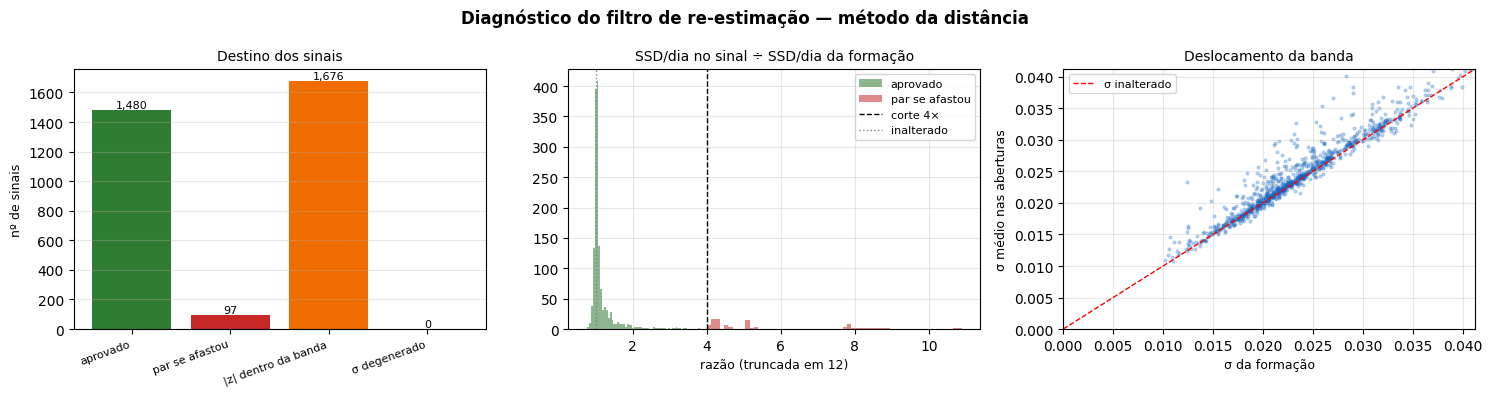

In [8]:
if len(eventos_df):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    fig.suptitle("Diagnóstico do filtro de re-estimação — método da distância",
                 fontsize=12, fontweight='bold')

    # 1) Destino dos sinais
    ordem  = ['aprovado', 'par_se_afastou', 'z_reestimado_dentro_da_banda', 'sigma_degenerado']
    rotulo = ['aprovado', 'par se afastou', '|z| dentro da banda', 'σ degenerado']
    cores  = ['#2E7D32', '#C62828', '#EF6C00', '#616161']
    cont   = [(eventos_df['motivo'] == m).sum() for m in ordem]

    axes[0].bar(range(len(ordem)), cont, color=cores)
    axes[0].set_xticks(range(len(ordem)))
    axes[0].set_xticklabels(rotulo, rotation=20, ha='right', fontsize=8)
    axes[0].set_title("Destino dos sinais", fontsize=10)
    axes[0].set_ylabel("nº de sinais", fontsize=9)
    for i, v in enumerate(cont):
        axes[0].text(i, v, f"{v:,}", ha='center', va='bottom', fontsize=8)
    axes[0].grid(alpha=0.3, axis='y')

    # 2) Afastamento no instante do sinal — aprovados × vetados
    ax = axes[1]
    for m, cor, lbl in [('aprovado', '#2E7D32', 'aprovado'),
                        ('par_se_afastou', '#C62828', 'par se afastou')]:
        s = eventos_df.loc[eventos_df['motivo'] == m, 'razao_ssd'].dropna()
        if len(s):
            ax.hist(s.clip(upper=12), bins=60, alpha=0.55, color=cor, label=lbl)
    if MAX_RAZAO_SSD is not None:
        ax.axvline(MAX_RAZAO_SSD, color='black', ls='--', lw=1,
                   label=f'corte {MAX_RAZAO_SSD:g}×')
    ax.axvline(1.0, color='gray', ls=':', lw=1, label='inalterado')
    ax.set_title("SSD/dia no sinal ÷ SSD/dia da formação", fontsize=10)
    ax.set_xlabel("razão (truncada em 12)", fontsize=9)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

    # 3) σ re-estimado × σ da formação
    ax = axes[2]
    cs = resultados_df.dropna(subset=['sigma_medio'])
    if len(cs):
        ax.scatter(cs['sigma'], cs['sigma_medio'], s=4, alpha=0.25, color='#1565C0')
        lim = [0, float(max(cs['sigma'].quantile(0.99), cs['sigma_medio'].quantile(0.99)))]
        ax.plot(lim, lim, color='red', ls='--', lw=1, label='σ inalterado')
        ax.set_xlim(lim); ax.set_ylim(lim)
        ax.legend(fontsize=8)
    ax.set_xlabel("σ da formação", fontsize=9)
    ax.set_ylabel("σ médio nas aberturas", fontsize=9)
    ax.set_title("Deslocamento da banda", fontsize=10)
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

## 6. Resultado por par

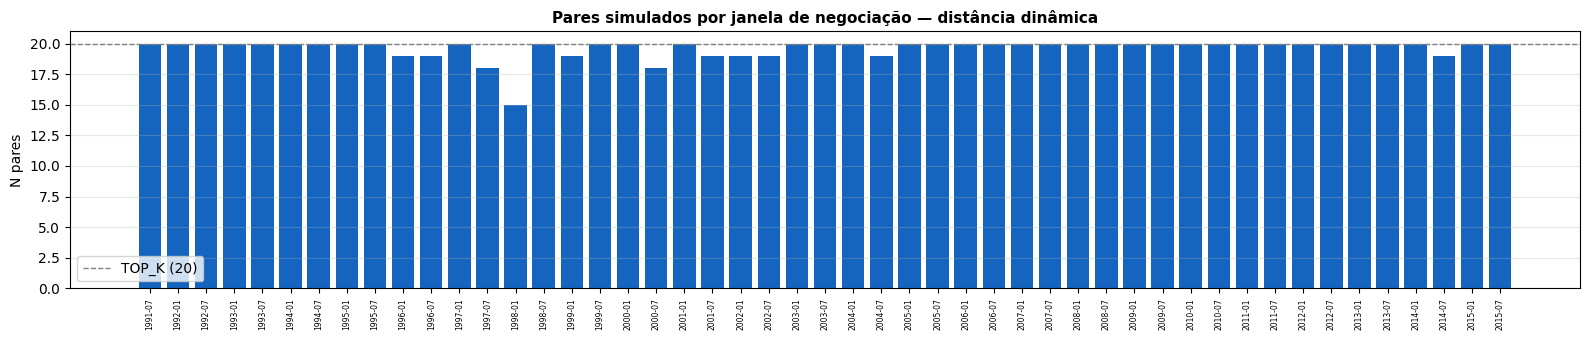

Janelas com 0 pares simulados : 0
Média de pares por janela     : 19.7
Mínimo / Máximo               : 15 / 20


In [9]:
# Pares simulados por janela de negociação
pares_por_janela = (
    resultados_df
    .groupby('neg_inicio')['ativo1']
    .count()
    .reset_index()
    .rename(columns={'ativo1': 'n_simulados'})
    .sort_values('neg_inicio')
)

fig, ax = plt.subplots(figsize=(16, 3.5))
cores = ['#1565C0' if n >= 10 else '#ef5350' for n in pares_por_janela['n_simulados']]
ax.bar(pares_por_janela['neg_inicio'], pares_por_janela['n_simulados'], color=cores)
ax.axhline(pares['rank'].max(), color='gray', lw=1.0, ls='--',
           label=f'TOP_K ({pares["rank"].max()})')
ax.set_title('Pares simulados por janela de negociação — distância dinâmica',
             fontsize=11, fontweight='bold')
ax.set_ylabel('N pares')
ax.tick_params(axis='x', rotation=90, labelsize=5.5)
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Janelas com 0 pares simulados : {(pares_por_janela['n_simulados'] == 0).sum()}")
print(f"Média de pares por janela     : {pares_por_janela['n_simulados'].mean():.1f}")
print(f"Mínimo / Máximo               : {pares_por_janela['n_simulados'].min()} / {pares_por_janela['n_simulados'].max()}")

In [10]:
pares_com_trade = resultados_df[resultados_df['n_trades'] > 0]

print("=== Estatísticas de trades ===")
print(f"Pares que abriram ≥ 1 trade    : {len(pares_com_trade):,} de {len(resultados_df):,}")
print(f"Total de trades abertos        : {resultados_df['n_trades'].sum():,}")
print(f"Trades fechados normalmente    : {resultados_df['n_fechados'].sum():,}")
print(f"Trades forçados (fim período)  : {resultados_df['n_forcados'].sum():,}")

if resultados_df['n_trades'].sum() > 0:
    taxa_convergencia = resultados_df['n_fechados'].sum() / resultados_df['n_trades'].sum()
    print(f"\nTaxa de convergência           : {taxa_convergencia:.1%}")

print("\n=== Retorno por par (todos os pares) ===")
print(resultados_df['retorno_total'].describe().to_string())

=== Estatísticas de trades ===
Pares que abriram ≥ 1 trade    : 942 de 963
Total de trades abertos        : 1,480
Trades fechados normalmente    : 759
Trades forçados (fim período)  : 721

Taxa de convergência           : 51.3%

=== Retorno por par (todos os pares) ===
count    963.000000
mean       0.015214
std        0.104648
min       -0.651787
25%       -0.035393
50%        0.014613
75%        0.073293
max        0.406175


In [11]:
print("Top 10 pares por retorno total:")
display(
    resultados_df
    .nlargest(10, 'retorno_total')
    [['neg_inicio', 'ativo1', 'ativo2', 'rank', 'sigma', 'sigma_medio',
      'n_sinais', 'n_trades', 'n_fechados', 'retorno_total']]
    .reset_index(drop=True)
)

print("\nBottom 10 pares por retorno total:")
display(
    resultados_df
    .nsmallest(10, 'retorno_total')
    [['neg_inicio', 'ativo1', 'ativo2', 'rank', 'sigma', 'sigma_medio',
      'n_sinais', 'n_trades', 'n_fechados', 'retorno_total']]
    .reset_index(drop=True)
)

Top 10 pares por retorno total:


,neg_inicio,ativo1,ativo2,rank,sigma,sigma_medio,n_sinais,n_trades,n_fechados,retorno_total
0,2000-01,SKY,FE,5,0.030164,0.031629,4,4,3,0.406175
1,2000-01,CNP,TEG,13,0.024919,0.028654,18,4,4,0.348081
2,2001-01,PLD,GRMN,15,0.041530,0.054915,30,3,3,0.347293
3,2000-01,TEG,DDR,14,0.033657,0.033660,3,3,3,0.344193
4,2007-07,9876566D,CLX,13,0.023270,0.026039,14,4,4,0.338794
5,1999-01,RDPL,300583Q,13,0.032033,0.036876,4,3,3,0.337974
6,2008-07,SWY,CMS,8,0.026892,0.028146,6,4,3,0.334903
7,2004-01,HSY,605018Q,14,0.025899,0.035398,3,3,2,0.319251
8,2002-07,2676187Q,BXP,12,0.030602,0.031795,7,4,4,0.318383
9,2000-01,DUK,TEG,7,0.021151,0.029159,4,3,3,0.315109



Bottom 10 pares por retorno total:


,neg_inicio,ativo1,ativo2,rank,sigma,sigma_medio,n_sinais,n_trades,n_fechados,retorno_total
0,2002-07,TXU,SCG,17,0.031694,0.032114,1,1,0,-0.651787
1,2000-07,NCC,HBAN,19,0.033657,0.033463,1,1,0,-0.450174
2,2000-07,PPL,HCN,20,0.034197,0.037915,6,2,1,-0.426429
3,2000-07,41018Q,BBT,17,0.033748,0.034173,1,1,0,-0.374141
4,1995-01,RHDCQ,L,12,0.023918,0.024334,1,1,0,-0.337004
5,2006-01,BLS,HBAN,20,0.021046,0.020916,1,1,0,-0.317472
6,2012-01,DIS,WU,20,0.023664,0.023966,1,1,0,-0.317341
7,2001-07,RDPL,JNJ,19,0.040736,0.041030,1,1,0,-0.310412
8,1999-07,GPC,LUK,17,0.031666,0.032522,1,1,0,-0.308095
9,2008-01,CLX,TE,17,0.026622,0.027167,5,3,2,-0.307310


## 7. Portfólio e curva de equity

Mesma convenção do notebook estático: o retorno diário do portfólio é a média dos retornos de
todos os pares ativos no dia, somando as carteiras sobrepostas.

- **`COMMITTED_CAPITAL = True`** (Gatev et al., 2006): todos os N pares entram no denominador
  todos os dias; pares sem posição contribuem 0. Um veto dinâmico, portanto, **não** aumenta o
  peso dos pares que negociaram — ele simplesmente deixa aquele capital em caixa, exatamente
  como um par que não deu sinal.
- **`COMMITTED_CAPITAL = False`** ("fully invested"): só pares com posição ativa entram na média.

In [12]:
portfolio = pd.Series(
    {date: np.mean(rets) for date, rets in retornos_por_data.items()}
).sort_index()

equity = (1 + portfolio).cumprod()

print(f"Período do portfólio: {portfolio.index[0].date()} → {portfolio.index[-1].date()}")
print(f"Dias de negociação  : {len(portfolio):,}")
print(f"Retorno diário médio: {portfolio.mean():.4%}")
print(f"Retorno acumulado   : {equity.iloc[-1] - 1:.2%}")

Período do portfólio: 1991-07-01 → 2015-12-31
Dias de negociação  : 6,174
Retorno diário médio: 0.0118%
Retorno acumulado   : 103.11%


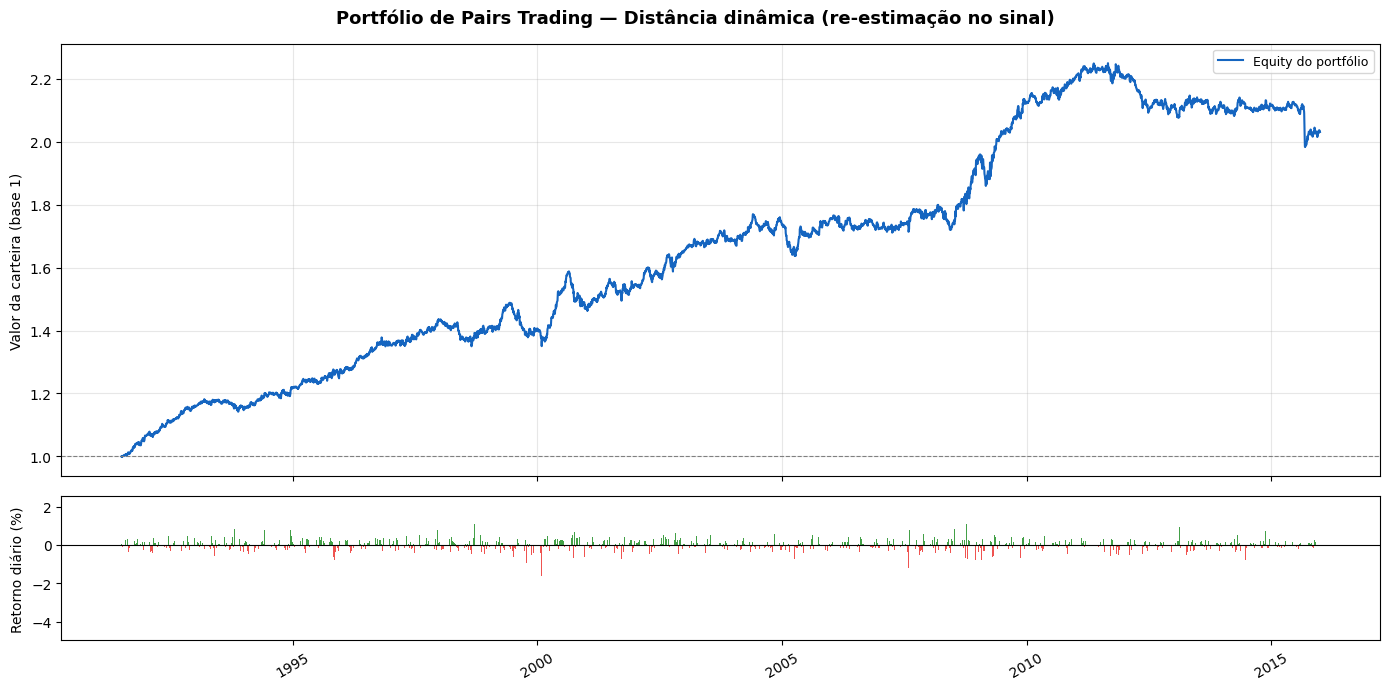

In [13]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True,
                          gridspec_kw={'height_ratios': [3, 1]})
fig.suptitle("Portfólio de Pairs Trading — Distância dinâmica (re-estimação no sinal)",
             fontsize=13, fontweight='bold')

ax_eq = axes[0]
ax_eq.plot(equity.index, equity.values, color='#1565C0', lw=1.5, label='Equity do portfólio')
ax_eq.axhline(1, color='gray', lw=0.8, ls='--')
ax_eq.set_ylabel('Valor da carteira (base 1)', fontsize=10)
ax_eq.legend(fontsize=9)
ax_eq.grid(alpha=0.3)

ax_ret = axes[1]
colors = ['#ef5350' if r < 0 else '#43A047' for r in portfolio.values]
ax_ret.bar(portfolio.index, portfolio.values * 100, color=colors, width=1)
ax_ret.axhline(0, color='black', lw=0.8)
ax_ret.set_ylabel('Retorno diário (%)', fontsize=10)
ax_ret.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax_ret.xaxis.set_major_locator(mdates.YearLocator(5))
ax_ret.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

## 8. Métricas de performance

In [14]:
sharpe             = portfolio.mean() / portfolio.std() * np.sqrt(252)
rolling_max        = equity.cummax()
drawdown           = (equity - rolling_max) / rolling_max
max_dd             = drawdown.min()
n_anos             = len(portfolio) / 252
retorno_anualizado = equity.iloc[-1] ** (1 / n_anos) - 1
dias_positivos     = (portfolio > 0).mean()

print("=" * 40)
print("     MÉTRICAS DE PERFORMANCE")
print("=" * 40)
print(f"Retorno acumulado      : {equity.iloc[-1] - 1:>+.2%}")
print(f"Retorno anualizado     : {retorno_anualizado:>+.2%}")
print(f"Volatilidade anual     : {portfolio.std() * np.sqrt(252):>.2%}")
print(f"Sharpe ratio           : {sharpe:>+.2f}")
print(f"Drawdown máximo        : {max_dd:>+.2%}")
print(f"Dias com retorno > 0   : {dias_positivos:.1%}")
print("=" * 40)

     MÉTRICAS DE PERFORMANCE
Retorno acumulado      : +103.11%
Retorno anualizado     : +2.93%
Volatilidade anual     : 4.30%
Sharpe ratio           : +0.69
Drawdown máximo        : -11.84%
Dias com retorno > 0   : 51.4%


### 8.1 Retorno bruto × retorno líquido de renda fixa

As mesmas métricas sobre duas séries: **bruto** ($r_p$) e **líquido** ($r_p - r_f$), com a taxa
diária de `rf_diario.csv` (Rf do professor até 2015-12-30 + T-bill de 3 meses do FRED em diante),
gerada por [`serie_rf.ipynb`](../database_formation/serie_rf.ipynb).

> Gatev et al. (2006, nota 5) e Sabino da Silva, Ziegelmann & Caldeira (2023, nota 10) assumem
> juro zero sobre o caixa ocioso e já chamam esse número de *excess return*. A coluna **líquido**
> aplica a subtração explícita, para comparação direta. Subtrair $r_f$ reduz a média mas não
> altera a volatilidade — o efeito recai quase todo sobre o Sharpe.

In [15]:
PATH_RF = '../../data_bases/rf_diario.csv'

rf = pd.read_csv(PATH_RF, parse_dates=['date']).set_index('date')['rf']
rf = rf.reindex(portfolio.index)

if rf.isna().any():
    print(f"⚠ {rf.isna().sum()} dia(s) do portfólio sem taxa — preenchidos com o último valor disponível.\n")
    rf = rf.ffill().bfill()

portfolio_liquido = portfolio - rf


def metricas_performance(serie):
    """Métricas anualizadas de uma série de retornos diários."""
    equity  = (1 + serie).cumprod()
    maxacum = equity.cummax()
    n_anos  = len(serie) / 252
    return {
        'Retorno acumulado'    : equity.iloc[-1] - 1,
        'Retorno anualizado'   : equity.iloc[-1] ** (1 / n_anos) - 1,
        'Média diária × 252'   : serie.mean() * 252,
        'Volatilidade anual'   : serie.std() * np.sqrt(252),
        'Sharpe ratio'         : serie.mean() / serie.std() * np.sqrt(252),
        'Drawdown máximo'      : ((equity - maxacum) / maxacum).min(),
        'Dias com retorno > 0' : (serie > 0).mean(),
    }


bruto   = metricas_performance(portfolio)
liquido = metricas_performance(portfolio_liquido)

rf_aa = (1 + rf.mean()) ** 252 - 1
print(f"Renda fixa no período : {rf_aa:.2%} a.a. (média diária de {rf.mean():.6f})")
print(f"Período               : {portfolio.index[0].date()} → {portfolio.index[-1].date()}  "
      f"({len(portfolio):,} dias)")
print()

print("=" * 66)
print("   MÉTRICAS DE PERFORMANCE — bruto × líquido de renda fixa")
print("=" * 66)
print(f"{'':<24}{'bruto':>13}{'líquido':>13}{'diferença':>14}")
print("-" * 66)
SEM_SINAL = {'Volatilidade anual', 'Dias com retorno > 0'}
for nome in bruto:
    b, l, d = bruto[nome], liquido[nome], liquido[nome] - bruto[nome]
    if nome == 'Sharpe ratio':
        print(f"{nome:<24}{b:>13.2f}{l:>13.2f}{d:>+14.2f}")
    elif nome in SEM_SINAL:
        print(f"{nome:<24}{b:>13.2%}{l:>13.2%}{d:>+14.2%}")
    else:
        print(f"{nome:<24}{b:>+13.2%}{l:>+13.2%}{d:>+14.2%}")
print("=" * 66)

⚠ 1 dia(s) do portfólio sem taxa — preenchidos com o último valor disponível.

Renda fixa no período : 2.65% a.a. (média diária de 0.000104)
Período               : 1991-07-01 → 2015-12-31  (6,174 dias)

   MÉTRICAS DE PERFORMANCE — bruto × líquido de renda fixa
                                bruto      líquido     diferença
------------------------------------------------------------------
Retorno acumulado            +103.11%       +6.89%       -96.21%
Retorno anualizado             +2.93%       +0.27%        -2.66%
Média diária × 252             +2.98%       +0.36%        -2.62%
Volatilidade anual              4.30%        4.30%        +0.00%
Sharpe ratio                     0.69         0.08         -0.61
Drawdown máximo               -11.84%      -17.38%        -5.54%
Dias com retorno > 0           51.36%       49.56%        -1.80%


Meses positivos: 179 de 294  (61%)


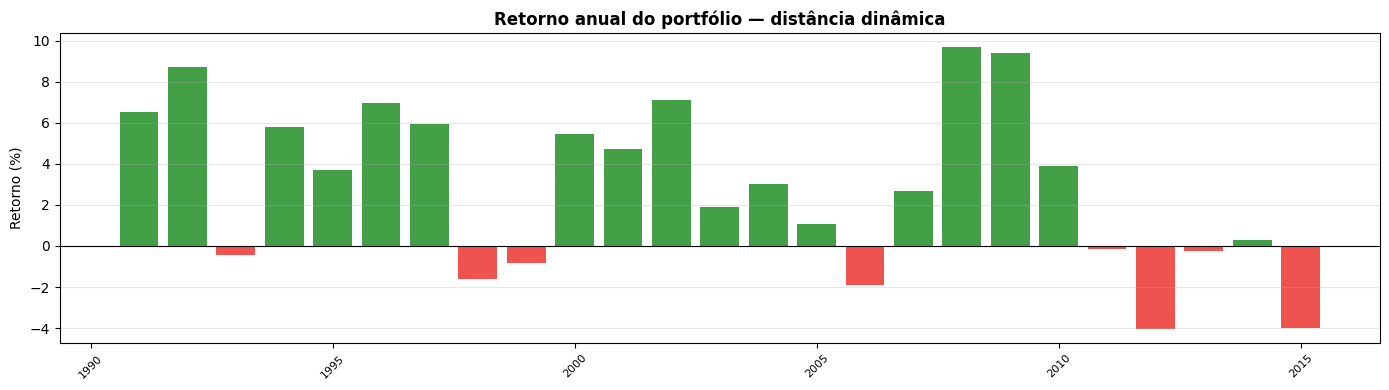

In [16]:
# Retorno por mês / ano de negociação
port_df = portfolio.to_frame('retorno')
port_df['ano']     = port_df.index.year
port_df['ano_mes'] = port_df.index.to_period('M').astype(str)

retorno_mensal = (
    port_df.groupby('ano_mes')['retorno']
    .apply(lambda r: (1 + r).prod() - 1)
    .reset_index()
    .rename(columns={'retorno': 'retorno_mensal'})
)

print(f"Meses positivos: {(retorno_mensal['retorno_mensal'] > 0).sum()} "
      f"de {len(retorno_mensal)}  ({(retorno_mensal['retorno_mensal'] > 0).mean():.0%})")

retorno_anual = (
    port_df.groupby('ano')['retorno']
    .apply(lambda r: (1 + r).prod() - 1)
    .reset_index()
    .rename(columns={'retorno': 'retorno_anual'})
)

fig, ax = plt.subplots(figsize=(14, 4))
cores = ['#43A047' if r > 0 else '#ef5350' for r in retorno_anual['retorno_anual']]
ax.bar(retorno_anual['ano'], retorno_anual['retorno_anual'] * 100, color=cores)
ax.axhline(0, color='black', lw=0.8)
ax.set_title('Retorno anual do portfólio — distância dinâmica', fontsize=12, fontweight='bold')
ax.set_ylabel('Retorno (%)')
ax.tick_params(axis='x', rotation=45, labelsize=8)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Estático × dinâmico

Compara este portfólio com o de `pairs_trading.ipynb` **nas mesmas datas**. Os dois partem do
mesmo `pares_formados.csv` e usam a mesma convenção de P&L; a única diferença é o que acontece
no instante do sinal.

> Rode `pairs_trading.ipynb` com os mesmos `PERIODO_INICIO`/`PERIODO_FIM` antes desta célula.

⚠️  ATENÇÃO: output/resultados/negociacao_portfolio.csv é mais ANTIGO que pairs_trading.ipynb.
    O baseline pode ter sido gerado por uma versão anterior do notebook estático.
    Rode pairs_trading.ipynb de novo antes de ler a comparação abaixo.

   PORTFÓLIO — ESTÁTICO × DINÂMICO   (mesmas datas, sem custos)
                              estático        dinâmico       diferença
--------------------------------------------------------------------------
Retorno acumulado             130.63%         103.11%         -27.52%
Retorno anualizado              3.47%           2.93%          -0.54%
Volatilidade anual              4.40%           4.30%          -0.10%
Sharpe ratio                      0.80            0.69           -0.10
Drawdown máximo               -12.12%         -11.84%          +0.28%
Dias positivos                 51.31%          51.36%          +0.05%

                                  estático      dinâmico
--------------------------------------------------------
Trade

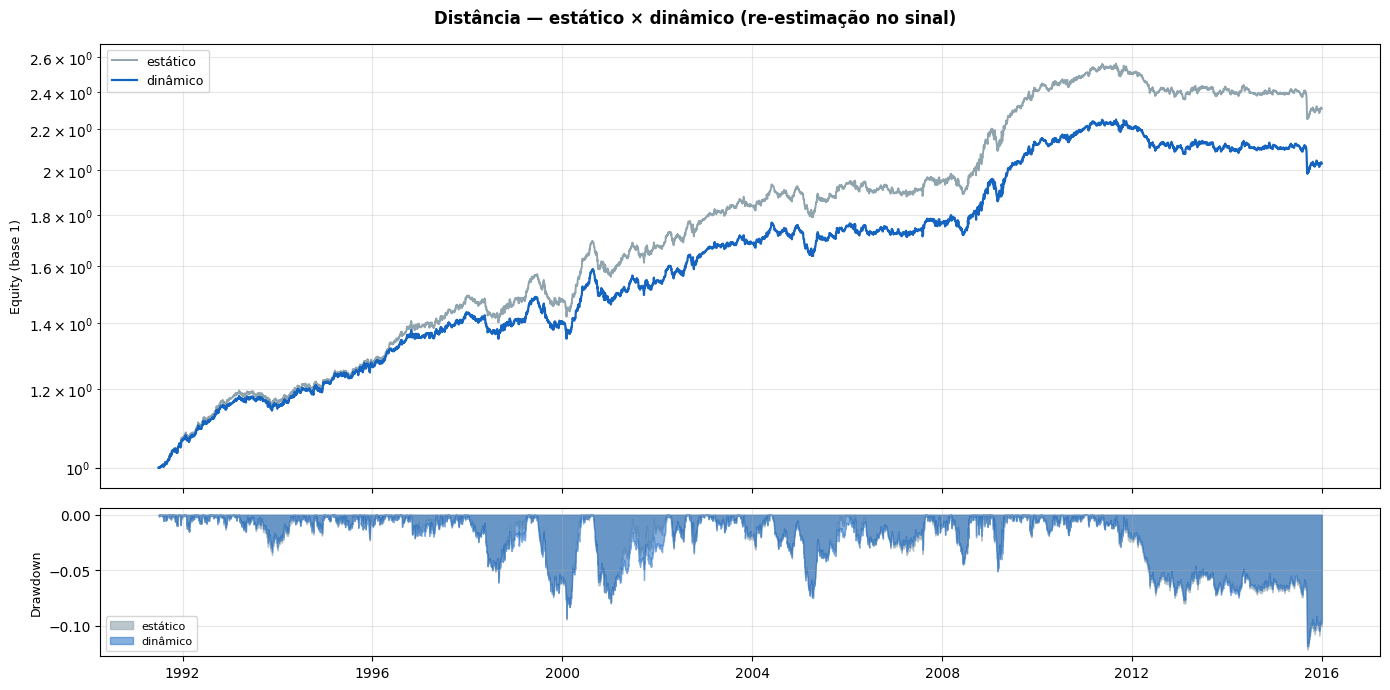

In [17]:
import os

PATH_BASE_PORT = 'output/resultados/negociacao_portfolio.csv'
PATH_BASE_PAR  = 'output/resultados/negociacao_pares.csv'

# O baseline é um CSV, não um cálculo: se ele foi gerado por uma versão anterior do notebook
# estático, a comparação mede a diferença entre as duas VERSÕES, não entre as duas estratégias.
# Já aconteceu: a mudança de `FECHA_NO_CRUZAMENTO` em 2026-09-14 vale +0,17 p.p. a.a. sozinha.
if os.path.exists(PATH_BASE_PORT) and os.path.getmtime(PATH_BASE_PORT) < os.path.getmtime('pairs_trading.ipynb'):
    print("⚠️  ATENÇÃO: output/resultados/negociacao_portfolio.csv é mais ANTIGO que pairs_trading.ipynb.")
    print("    O baseline pode ter sido gerado por uma versão anterior do notebook estático.")
    print("    Rode pairs_trading.ipynb de novo antes de ler a comparação abaixo.\n")

if not os.path.exists(PATH_BASE_PORT):
    print(f"Baseline estático não encontrado em {PATH_BASE_PORT}.")
    print("Rode pairs_trading.ipynb primeiro para gerar a comparação.")
else:
    # O estático salva a série com o índice sem nome (primeira coluna anônima), então lemos
    # por posição em vez de por nome — assim o notebook não quebra se o rótulo mudar.
    base_port = pd.read_csv(PATH_BASE_PORT, index_col=0, parse_dates=True)['retorno_diario']
    base_port.index.name = 'date'
    base_par  = pd.read_csv(PATH_BASE_PAR)

    # Datas em comum — garante que as métricas comparem o mesmo período
    idx = portfolio.index.intersection(base_port.index)
    est = base_port.reindex(idx)
    din = portfolio.reindex(idx)

    if len(idx) < len(portfolio) or len(idx) < len(base_port):
        print(f"⚠️  Períodos diferem: dinâmico {len(portfolio):,} dias, "
              f"estático {len(base_port):,} dias → comparando {len(idx):,} dias em comum.\n")

    def metricas(s):
        eq = (1 + s).cumprod()
        dd = (eq - eq.cummax()) / eq.cummax()
        return {
            'Retorno acumulado' : eq.iloc[-1] - 1,
            'Retorno anualizado': eq.iloc[-1] ** (252 / len(s)) - 1,
            'Volatilidade anual': s.std() * np.sqrt(252),
            'Sharpe ratio'      : s.mean() / s.std() * np.sqrt(252),
            'Drawdown máximo'   : dd.min(),
            'Dias positivos'    : (s > 0).mean(),
        }

    m_est, m_din = metricas(est), metricas(din)

    print("=" * 74)
    print("   PORTFÓLIO — ESTÁTICO × DINÂMICO   (mesmas datas, sem custos)")
    print("=" * 74)
    print(f"{'':<22}{'estático':>16}{'dinâmico':>16}{'diferença':>16}")
    print("-" * 74)
    for k in m_est:
        a, b = m_est[k], m_din[k]
        if k == 'Sharpe ratio':
            print(f"{k:<22}{a:>16.2f}{b:>16.2f}{b - a:>+16.2f}")
        else:
            print(f"{k:<22}{a:>15.2%}{b:>16.2%}{b - a:>+16.2%}")
    print("=" * 74)

    # ── Trades ────────────────────────────────────────────────────────────────────
    def conv(d):
        tot = d['n_trades'].sum()
        return d['n_fechados'].sum() / tot if tot else np.nan

    print(f"\n{'':<28}{'estático':>14}{'dinâmico':>14}")
    print("-" * 56)
    print(f"{'Trades abertos':<28}{base_par['n_trades'].sum():>14,}"
          f"{resultados_df['n_trades'].sum():>14,}")
    print(f"{'Fechados por reversão':<28}{base_par['n_fechados'].sum():>14,}"
          f"{resultados_df['n_fechados'].sum():>14,}")
    print(f"{'Forçados (fim do período)':<28}{base_par['n_forcados'].sum():>14,}"
          f"{resultados_df['n_forcados'].sum():>14,}")
    print(f"{'Taxa de convergência':<28}{conv(base_par):>13.1%}{conv(resultados_df):>14.1%}")
    print(f"{'Retorno médio por par':<28}{base_par['retorno_total'].mean():>13.2%}"
          f"{resultados_df['retorno_total'].mean():>14.2%}")
    print(f"{'Sinais avaliados':<28}{'—':>14}{resultados_df['n_sinais'].sum():>14,}")
    print("\nNota: 'sinais avaliados' não tem contrapartida no estático — lá todo sinal vira")
    print("trade. As duas contagens não são pareáveis: um sinal vetado devolve o par ao")
    print("monitoramento, e ele volta a cruzar a banda mais adiante.")
    if MODO_BANDA != 'movel' and FECHA_NO_CRUZAMENTO:
        print("Config atual: gatilho e saída idênticos ao estático → o dinâmico é um FILTRO")
        print("estrito sobre os trades do estático. Toda a diferença de desempenho vem dos")
        print("sinais recusados pela revalidação / dupla confirmação.")

    # ── Curvas de equity e drawdown ───────────────────────────────────────────────
    eq_est, eq_din = (1 + est).cumprod(), (1 + din).cumprod()
    dd_est = (eq_est - eq_est.cummax()) / eq_est.cummax()
    dd_din = (eq_din - eq_din.cummax()) / eq_din.cummax()

    fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True,
                             gridspec_kw={'height_ratios': [3, 1]})
    fig.suptitle("Distância — estático × dinâmico (re-estimação no sinal)",
                 fontsize=12, fontweight='bold')

    ax = axes[0]
    ax.plot(eq_est.index, eq_est.values, color='#90A4AE', lw=1.4, label='estático')
    ax.plot(eq_din.index, eq_din.values, color='#1565C0', lw=1.6, label='dinâmico')
    ax.set_ylabel("Equity (base 1)", fontsize=9)
    ax.set_yscale('log')
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3, which='both')

    ax = axes[1]
    ax.fill_between(dd_est.index, dd_est.values, 0, color='#90A4AE', alpha=0.6, label='estático')
    ax.fill_between(dd_din.index, dd_din.values, 0, color='#1565C0', alpha=0.5, label='dinâmico')
    ax.set_ylabel("Drawdown", fontsize=9)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

## 10. Explorando um par específico

Mostra lado a lado o z de monitoramento (parâmetros da formação) e o z do trade (parâmetros
re-estimados), com cada sinal marcado: ○ aprovado, ✕ vetado.

In [18]:
# === Configuração: escolha o par a explorar ===
NEG_INICIO_ALVO = '2020-07'   # mês inicial do período de negociação ('YYYY-MM')
RANK_ALVO       = 1           # rank do par (1–TOP_K)

sel = pares[(pares['negociacao_inicio'] == NEG_INICIO_ALVO) & (pares['rank'] == RANK_ALVO)]
if sel.empty:   # a janela pedida não existe na grade atual — usa a primeira disponível
    NEG_INICIO_ALVO = resultados_df['neg_inicio'].iloc[0]
    sel = pares[(pares['negociacao_inicio'] == NEG_INICIO_ALVO) & (pares['rank'] == RANK_ALVO)]

par_info = sel.iloc[0]

print(f"Par selecionado : {par_info['ativo1']} / {par_info['ativo2']}")
print(f"Janela          : {par_info['janela']}")
print(f"Negociação      : {par_info['negociacao_inicio']} → {par_info['negociacao_fim']}")
print(f"SSD             : {par_info['ssd']:.6f}")
print(f"Spread μ        : {par_info['spread_media']:.6f}")
print(f"Spread σ        : {par_info['spread_desvio']:.6f}")

Par selecionado : GPUI / FPC
Janela          : 1990-07_a_1991-06
Negociação      : 1991-07 → 1991-12
SSD             : 0.081123
Spread μ        : 0.002994
Spread σ        : 0.017726


In [19]:
a1 = par_info['ativo1']
a2 = par_info['ativo2']

form_inicio = pd.Period(par_info['formacao_inicio'],   freq='M')
form_fim    = pd.Period(par_info['formacao_fim'],      freq='M')
neg_inicio  = pd.Period(par_info['negociacao_inicio'], freq='M')
neg_fim     = pd.Period(par_info['negociacao_fim'],    freq='M')

mask_form = (meses_por_linha >= form_inicio) & (meses_por_linha <= form_fim)
mask_neg  = (meses_por_linha >= neg_inicio)  & (meses_por_linha <= neg_fim)

precos_form = df.loc[mask_form, [a1, a2]].dropna()
precos_neg  = df.loc[mask_neg,  [a1, a2]].dropna()

resultado, info = simular_par_dist_dinamico(
    precos_form, precos_neg, par_info['spread_media'], par_info['spread_desvio']
)

if resultado is None:
    print("Par não pode ser simulado.")
else:
    n_ab, n_fec, n_for = contar_trades(resultado['position'].values)
    print(f"Sinais gerados    : {info['n_sinais']}")
    print(f"  aprovados       : {info['n_aprovados']}")
    print(f"  par se afastou  : {info['n_rej_ssd']}")
    print(f"  σ degenerado    : {info['n_rej_sigma']}")
    print(f"  |z| na banda    : {info['n_rej_z']}")
    print(f"Trades abertos    : {n_ab}")
    print(f"Fechados (z→0)    : {n_fec}")
    print(f"Forçados          : {n_for}")
    if np.isfinite(info['sigma_medio']):
        print(f"σ formação → médio nas aberturas : "
              f"{par_info['spread_desvio']:.6f} → {info['sigma_medio']:.6f}")
        print(f"μ formação → médio nas aberturas : "
              f"{par_info['spread_media']:.6f} → {info['mu_medio']:.6f}")
    print(f"Retorno total     : {resultado['retorno_diario'].sum():+.4%}")

    if info['eventos']:
        display(pd.DataFrame(info['eventos']))

Sinais gerados    : 2
  aprovados       : 2
  par se afastou  : 0
  σ degenerado    : 0
  |z| na banda    : 0
Trades abertos    : 2
Fechados (z→0)    : 1
Forçados          : 1
σ formação → médio nas aberturas : 0.017726 → 0.017706
μ formação → médio nas aberturas : 0.002994 → 0.003802
Retorno total     : +3.2680%


,data,motivo,n_amostra,z_monitor,z_movel,z_novo,mu_novo,sigma_novo,razao_ssd
0,1991-08-12,aprovado,282,2.240416,2.189691,2.189691,0.004036,0.017660,1.016021
1,1991-09-26,aprovado,314,-2.245498,-2.274594,-2.274594,0.003568,0.017751,1.015228


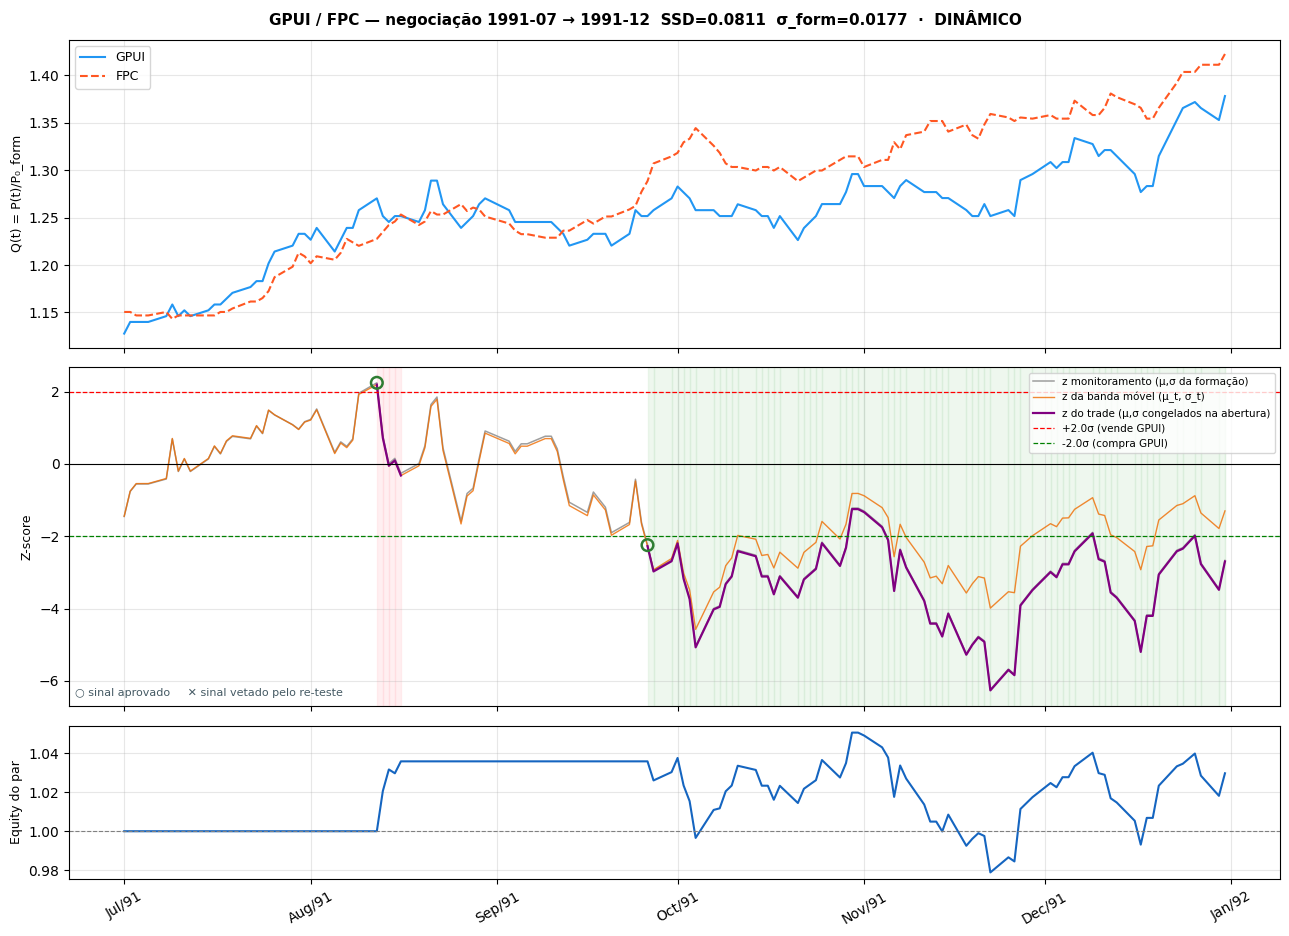

In [20]:
if resultado is not None:
    P0         = precos_form.sort_index().iloc[0]
    Q_neg      = precos_neg / P0
    equity_par = (1 + resultado['retorno_diario']).cumprod()

    fig, axes = plt.subplots(3, 1, figsize=(13, 9.5), sharex=True,
                             gridspec_kw={'height_ratios': [2, 2.2, 1]})
    fig.suptitle(
        f"{a1} / {a2} — negociação {par_info['negociacao_inicio']} → {par_info['negociacao_fim']}  "
        f"SSD={par_info['ssd']:.4f}  σ_form={par_info['spread_desvio']:.4f}  ·  DINÂMICO",
        fontsize=11, fontweight='bold'
    )

    # Painel 1: preços normalizados Q(t) no período de negociação
    ax1 = axes[0]
    ax1.plot(Q_neg.index, Q_neg[a1], color='#2196F3', lw=1.5, label=a1)
    ax1.plot(Q_neg.index, Q_neg[a2], color='#FF5722', lw=1.5, ls='--', label=a2)
    ax1.set_ylabel('Q(t) = P(t)/P₀_form', fontsize=9)
    ax1.legend(fontsize=9)
    ax1.grid(alpha=0.3)

    # Painel 2: z de monitoramento × z do trade + sinais vetados
    ax2 = axes[1]
    ax2.plot(resultado.index, resultado['z_monitor'], color='#9E9E9E', lw=1.1,
             label='z monitoramento (μ,σ da formação)')
    ax2.plot(resultado.index, resultado['z_movel'], color='#EF6C00', lw=1.0, alpha=0.8,
             label='z da banda móvel (μ_t, σ_t)')
    ax2.plot(resultado.index, resultado['z_trade'], color='purple', lw=1.6,
             label='z do trade (μ,σ congelados na abertura)')
    ax2.axhline(0,      color='black', lw=0.8)
    ax2.axhline(+DELTA, color='red',   lw=0.9, ls='--', label=f'+{DELTA}σ (vende {a1})')
    ax2.axhline(-DELTA, color='green', lw=0.9, ls='--', label=f'-{DELTA}σ (compra {a1})')
    if STOP is not None:
        ax2.axhline(+STOP, color='red',   lw=0.7, ls=':', alpha=0.5)
        ax2.axhline(-STOP, color='green', lw=0.7, ls=':', alpha=0.5)

    # Marca cada sinal avaliado: ○ aprovado, ✕ vetado
    for ev in info['eventos']:
        aprov = ev['motivo'] == 'aprovado'
        ax2.scatter(ev['data'], ev['z_monitor'],
                    marker='o' if aprov else 'x',
                    s=70 if aprov else 90,
                    facecolors='none' if aprov else '#C62828',
                    edgecolors='#2E7D32' if aprov else '#C62828',
                    linewidths=1.8, zorder=5)

    # Sombreia os dias posicionados
    pos_arr, datas = resultado['position'].values, resultado.index
    for t in range(len(pos_arr)):
        if pos_arr[t] != 0:
            cor = '#FFCDD2' if pos_arr[t] == -1 else '#C8E6C9'
            ax2.axvspan(datas[t], datas[min(t + 1, len(datas) - 1)], alpha=0.3, color=cor)

    ax2.set_ylabel('Z-score', fontsize=9)
    ax2.legend(fontsize=7.5, loc='upper right')
    ax2.grid(alpha=0.3)
    ax2.text(0.005, 0.03, "○ sinal aprovado     ✕ sinal vetado pelo re-teste",
             transform=ax2.transAxes, fontsize=8, color='#455A64')

    # Painel 3: equity acumulada do par
    ax3 = axes[2]
    ax3.plot(equity_par.index, equity_par.values, color='#1565C0', lw=1.5)
    ax3.axhline(1, color='gray', lw=0.8, ls='--')
    ax3.set_ylabel('Equity do par', fontsize=9)
    ax3.xaxis.set_major_formatter(mdates.DateFormatter('%b/%y'))
    ax3.tick_params(axis='x', rotation=30)
    ax3.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

## 11. Sensibilidade às escolhas dinâmicas

O notebook tem quatro decisões que não são forçadas pela teoria: quem dispara o sinal, qual a
amostra da re-estimação, se há veto por afastamento e se há dupla confirmação. A célula abaixo
roda o portfólio inteiro em cada configuração e mostra o efeito de cada uma isoladamente, para
que a escolha do default fique explícita em vez de embutida.

A primeira linha é o **estático reproduzido dentro deste notebook** — não o CSV salvo — de modo
que a comparação não depende de o baseline estar atualizado.

In [21]:
# Reaproveita os recortes de preço uma vez só; cada cenário custa poucos segundos.
_recortes = []
for _, _par in pares.iterrows():
    _a1, _a2 = _par['ativo1'], _par['ativo2']
    if _par['spread_desvio'] < SIGMA_MIN or _a1 not in df.columns or _a2 not in df.columns:
        continue
    _mf = ((meses_por_linha >= pd.Period(_par['formacao_inicio'], 'M')) &
           (meses_por_linha <= pd.Period(_par['formacao_fim'], 'M')))
    _mn = ((meses_por_linha >= pd.Period(_par['negociacao_inicio'], 'M')) &
           (meses_por_linha <= pd.Period(_par['negociacao_fim'], 'M')))
    _pf, _pn = df.loc[_mf, [_a1, _a2]].dropna(), df.loc[_mn, [_a1, _a2]].dropna()
    if len(_pf) and len(_pn):
        _recortes.append((_par['spread_media'], _par['spread_desvio'], _pf, _pn, df.index[_mn]))


def _rodar_cenario(**kw):
    por_data, n_tr, n_fe, n_si, n_ap = {}, 0, 0, 0, 0
    for _mu, _sg, _pf, _pn, _datas in _recortes:
        _r, _i = simular_par_dist_dinamico(_pf, _pn, _mu, _sg, **kw)
        if _r is None:
            continue
        _a, _f, _ = contar_trades(_r['position'].values)
        n_tr += _a; n_fe += _f; n_si += _i['n_sinais']; n_ap += _i['n_aprovados']
        _d = _r['retorno_diario'].to_dict()
        if COMMITTED_CAPITAL:
            for _dt in _datas:
                por_data.setdefault(_dt, []).append(_d.get(_dt, 0.0))
        else:
            for _dt, _row in _r.iterrows():
                if _row['position_lag'] != 0:
                    por_data.setdefault(_dt, []).append(_row['retorno_diario'])
    _s = pd.Series({k: np.mean(v) for k, v in por_data.items()}).sort_index()
    _eq = (1 + _s).cumprod()
    return {
        'a.a.':     _eq.iloc[-1] ** (252 / len(_s)) - 1,
        'Sharpe':   _s.mean() / _s.std() * np.sqrt(252),
        'DD máx':   ((_eq - _eq.cummax()) / _eq.cummax()).min(),
        'trades':   n_tr,
        'conv.':    n_fe / n_tr if n_tr else np.nan,
        'sinais':   n_si,
        'aprov.':   n_ap / n_si if n_si else np.nan,
    }


CENARIOS = [
    ('estático (reproduzido aqui)', dict(max_razao=None, exige_z=False,
                                         modo_banda='formacao', modo='diario')),
    ('DEFAULT: formação + veto + dupla conf.', dict()),
    ('  só veto de afastamento',               dict(exige_z=False)),
    ('  só dupla confirmação',                 dict(max_razao=None)),
    ('  default, rolling 252',                 dict(janela=252)),
    ('  default, saída em μ re-estimado',      dict(fecha_no_cruzamento=False)),
    ('banda MÓVEL, expanding',                 dict(modo_banda='movel')),
    ('  banda MÓVEL, rolling 252',             dict(modo_banda='movel', janela=252)),
    ('  banda MÓVEL, rolling 126',             dict(modo_banda='movel', janela=126)),
]

_linhas = {}
for _nome, _kw in CENARIOS:
    _linhas[_nome] = _rodar_cenario(**_kw)

sensibilidade = pd.DataFrame(_linhas).T
display(sensibilidade.style.format({'a.a.': '{:.2%}', 'Sharpe': '{:.2f}', 'DD máx': '{:.1%}',
                                    'trades': '{:,.0f}', 'conv.': '{:.0%}',
                                    'sinais': '{:,.0f}', 'aprov.': '{:.0%}'}))

print("\nLeitura: a diferença entre a 1ª linha e cada uma das outras é atribuível APENAS à")
print("decisão dinâmica indicada — mesma base, mesmos pares, mesma convenção de P&L.")

,a.a.,Sharpe,DD máx,trades,conv.,sinais,aprov.
estático (reproduzido aqui),3.47%,0.80,-12.1%,"1,639",53%,"1,639",100%
DEFAULT: formação + veto + dupla conf.,2.93%,0.69,-11.8%,"1,480",51%,"3,253",45%
só veto de afastamento,3.45%,0.79,-12.1%,"1,626",53%,"1,723",94%
só dupla confirmação,2.94%,0.69,-11.8%,"1,485",51%,"3,235",46%
"default, rolling 252",2.89%,0.69,-11.5%,"1,447",51%,"3,770",38%
"default, saída em μ re-estimado",2.90%,0.68,-12.0%,"1,473",51%,"3,269",45%
"banda MÓVEL, expanding",2.94%,0.69,-11.6%,"1,489",51%,"1,498",99%
"banda MÓVEL, rolling 252",2.99%,0.70,-11.3%,"1,482",52%,"1,589",93%
"banda MÓVEL, rolling 126",2.65%,0.63,-10.2%,"1,541",56%,"2,397",64%



Leitura: a diferença entre a 1ª linha e cada uma das outras é atribuível APENAS à
decisão dinâmica indicada — mesma base, mesmos pares, mesma convenção de P&L.


## 12. Salvando resultados

In [22]:
SUFIXO = '_dinamico'

resultados_df.to_csv(f'output/resultados/negociacao_pares{SUFIXO}.csv', index=False)
portfolio.to_frame('retorno_diario').to_csv(f'output/resultados/negociacao_portfolio{SUFIXO}.csv')

# Log de todos os sinais avaliados — insumo da análise do filtro dinâmico
if len(eventos_df):
    eventos_df.to_csv(f'output/resultados/eventos_reteste{SUFIXO}.csv', index=False)

print("Salvo:")
print(f"  output/resultados/negociacao_pares{SUFIXO}.csv      — resultado por par (+ contadores de veto)")
print(f"  output/resultados/negociacao_portfolio{SUFIXO}.csv  — série diária do portfólio")
if len(eventos_df):
    print(f"  output/resultados/eventos_reteste{SUFIXO}.csv       — um registro por sinal avaliado")

Salvo:
  output/resultados/negociacao_pares_dinamico.csv      — resultado por par (+ contadores de veto)
  output/resultados/negociacao_portfolio_dinamico.csv  — série diária do portfólio
  output/resultados/eventos_reteste_dinamico.csv       — um registro por sinal avaliado
